# P3 · Notebook 02b: Semantic check, router and quality-gated cascade (GPU)

**The main idea of our project:** most prompts don't need the expensive setting. So we **start cheap, check the picture, and spend more compute only when it fails**.

```
prompt ─► router picks a starting level ─► SANA-Sprint draws ─► GATE: visual check (classical CV) + semantic check (detector + CLIP)
                                                ▲                         │ pass → done
                                                └── next level (more steps, bigger, NEW seed) ◄── fail
```

**What this notebook does:**
1. **Validates the measuring tools** on real COCO photos with ground truth: can our checkers tell a true checklist from a false one?
2. **Generates every prompt at every level**: training prompts and test prompts, kept strictly apart.
3. **Labels from experiments:** each *training* prompt's label is the **cheapest level whose picture passes the gate**.
4. **Trains the router** (prompt → starting level) and tests it on held-out prompts.
5. **Replays 6 strategies on the test prompts** (fixed levels, cascade, router, router + cascade) and compares speed against quality.
6. **Tests the original model** (the 20-step teacher, notebook 01's baseline) on the **same** test prompts with the **same** judge. That's what lets us say "better than / as good as the original".

**Two separate judges, so the cascade never grades its own homework:**

| | Detector | CLIP | Used for |
|---|---|---|---|
| **Gate** (fast) | Mask R-CNN v2 (torchvision) | ViT-B/16 | deciding *during* the cascade |
| **Judge** (independent) | **Mask2Former Swin-S**, the kind GenEval uses | **ViT-L/14**, same as notebook 01 | **scoring** every strategy |

All structured scores are **"GenEval-style"** (our re-implementation of GenEval's rules), **not** official GenEval numbers.

**Before running:**
- Runtime → **T4 GPU**.
- `RUNGS` are already set from notebook 01's T4 results: 768px → 1024px → 1024px, with a new seed at every level.
- QUICK mode ≈ 1–1.5 hours (including ~15–20 min for the original teacher). FULL mode ≈ 4–5 hours.
- Progress is saved to Drive. If Colab disconnects, **Run all** again.

## 1 · Settings

In [1]:
import os
QUICK = True
N_TRAIN_STRUCT = 120 if QUICK else 400    # our own GenEval-like prompts (same templates, none of GenEval's own)
N_TRAIN_COCO = 80 if QUICK else 300       # COCO *train* captions
N_TEST_GENEVAL = 120 if QUICK else 553    # official GenEval prompts (QUICK: equal share per task)
N_TEST_COCO = 80 if QUICK else 300        # COCO *val* captions
N_CHECKER_PHOTOS = 100 if QUICK else 300  # real COCO photos for validating the checkers
if os.environ.get("P3_TINY"):             # offline smoke test only
    N_TRAIN_STRUCT, N_TRAIN_COCO, N_TEST_GENEVAL, N_TEST_COCO, N_CHECKER_PHOTOS = 8, 4, 8, 4, 6

MODEL_REPO = "Efficient-Large-Model/Sana_Sprint_0.6B_1024px_diffusers"
TE_QUANT = None        # plain float16 = the fastest pipeline (S8/S1 timings); the app may use M3 to save memory
# The cascade's levels, cheapest first, chosen from notebook 01's T4 results:
#   2 steps @768px 0.96 s (CLIP 26.6) | 2 steps @1024px 1.23 s (CLIP 27.1); baseline teacher 5.54 s (CLIP 27.0)
#   - 512px is NOT used: the model was trained at 1024px and 512px pictures look visibly broken (hard-prompt grid)
#   - steps aren't the lever (1 step wasn't faster than 2, 4 steps didn't raise CLIP), so levels change size + seed
#   - every level uses a NEW seed, so a failed composition gets a genuinely new picture
RUNGS = [
    {"name": "R0", "steps": 2, "res": 768},
    {"name": "R1", "steps": 2, "res": 1024},
    {"name": "R2", "steps": 2, "res": 1024},
]
GATE_CLIP = "openai/clip-vit-base-patch16"
JUDGE_CLIP = "openai/clip-vit-large-patch14"
CLIP_MIN_PERCENTILE = 20   # gate: CLIP below the 20th percentile of top-level training pictures = "weak match"
RUN_TEACHER = True         # also test the ORIGINAL model (teacher, 20 steps) on the same test prompts (+15-20 min QUICK)
TEACHER_REPO = "Efficient-Large-Model/Sana_Sprint_0.6B_1024px_teacher_diffusers"
SEED = 0
SAVE_TO_DRIVE = True

## 2 · Install (~1–2 min)

In [2]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "diffusers", "transformers", "accelerate",
                "bitsandbytes", "scikit-learn", "tabulate", "sentencepiece", "protobuf"], check=True)
print("Libraries installed.")

Libraries installed.


## 3 · Our modules
Two cells write `p3_classical.py` (visual check, from notebook 02a) and `p3_semantic.py` (prompt reader + GenEval-style checker). They're the same files as `src/` in the repo, and they're copied to Drive (`P3_T2I/shared/`) for the app.

In [3]:
%%writefile p3_classical.py
"""p3_classical.py: the classical computer-vision layer of our P3 text-to-image system.

No neural networks in here, only image maths (OpenCV + NumPy). This layer judges VISUAL quality only.
Whether the picture matches the prompt (semantic quality) is checked elsewhere (CLIP + detector, notebook 02b).

    assess(img, prompt)        no-reference visual check -> metrics, flags, verdict ("ok" / "fix" / "regenerate")
    safe_enhance(img, prompt)  fix only what was flagged, re-check, and KEEP THE FIX ONLY IF IT HELPED
    quality_maps(img)          per-region detail / noise maps (so fixes touch only the regions that need them)
    upscale(img, size)         classical resizing, incl. an edge-aware upscaler (Lanczos + back-projection)
    pack_for_mobile(img)       resize + smallest WebP/JPEG that keeps SSIM >= target
    psnr(a, b), ssim(a, b)     reference metrics for the experiments

Images are RGB uint8 numpy arrays (H, W, 3). to_rgb() converts PIL images.
"""
from __future__ import annotations

import time

import cv2
import numpy as np

ANALYSIS_SIZE = 512  # checks run on a copy with this longest side, so thresholds don't depend on resolution

# Thresholds, calibrated on real photos + synthetic damage (notebook 02a re-validates them on held-out images).
TH = {
    "blank_std": 4.0,           # brightness spread below this -> blank / broken
    "dark_mean": 90.0,          # too dark: mean brightness below this ...
    "dark_p95": 135.0,          # ... AND even the brightest 5% are dim
    "bright_mean": 170.0,       # too bright / washed out: mean above this ...
    "bright_p5": 110.0,         # ... AND even the darkest 5% are light
    "low_contrast": 0.10,       # RMS contrast (std / 255) below this -> flat
    "blur": 0.04,               # contrast-normalised sharpness below this -> blurry
    "noise_sigma": 3.8,         # noise estimated in flat areas (grey levels) above this -> grainy
    "cast_gray": 13.0,          # colour shift of the near-grey pixels above this -> tint. Deliberately conservative:
                                # warm scenes (brown fur, lamp light) also score high, so only strong tints count
    "periodic": 2.5,            # FFT spike strength above this -> grid / checkerboard glitch
}

# Do-no-harm guard: a fix may not raise the noise estimate by more than this (grey levels), e.g. CLAHE/sharpening on sky.
MAX_ADDED_GRAIN = 1.5   # brightening alone adds ~+0.3 (reveals shadow noise); gamma+CLAHE can reach +2

# Problems a classical fix can't really undo: if they remain, the cascade should generate again with more steps.
UNFIXABLE = {"blank", "blurry", "noisy", "periodic_artifact"}

# Words in the prompt that mean "this look is intended, don't fix it".
INTENT = {
    "too_dark": ["night", "dark", "noir", "silhouette", "midnight", "shadow", "candlelit", "moody", "low light", "starry"],
    "too_bright": ["bright white", "overexposed", "high key", "snow", "foggy white", "minimalist white"],
    "low_contrast": ["fog", "foggy", "mist", "haze", "hazy", "pastel", "soft light", "dreamy", "minimalist"],
    "colour_cast": ["sunset", "sunrise", "golden", "neon", "sepia", "monochrome", "black and white",
                    "underwater", "vintage", "duotone", "red light", "blue light", "candle", "warm", "autumn",
                    "fire", "desert", "lamp", "cozy", "cosy", "tungsten", "night city"],
    "blurry": ["bokeh", "blurry", "blurred", "motion blur", "out of focus", "depth of field", "dreamy",
               "fog", "foggy", "mist", "long exposure", "soft focus"],
    "noisy": ["film grain", "grainy", "noise", "noisy", "vintage photo", "analog"],
}


# ----------------------------------------------------------------------------- helpers
def to_rgb(img) -> np.ndarray:
    """PIL image / array -> RGB uint8 array (H, W, 3)."""
    if hasattr(img, "convert"):
        return np.asarray(img.convert("RGB")).copy()
    a = np.asarray(img)
    if a.ndim == 2:
        a = np.stack([a] * 3, axis=-1)
    if a.dtype != np.uint8:
        a = np.clip(a, 0, 255).astype(np.uint8)
    return np.ascontiguousarray(a[..., :3])


def _analysis_view(rgb: np.ndarray) -> np.ndarray:
    h, w = rgb.shape[:2]
    s = ANALYSIS_SIZE / max(h, w)
    if s < 1:
        rgb = cv2.resize(rgb, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    return rgb


def _gray(rgb: np.ndarray) -> np.ndarray:
    return cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)


def _edge_strength(gray: np.ndarray) -> np.ndarray:
    g = gray.astype(np.float32)
    mag = cv2.magnitude(cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3), cv2.Sobel(g, cv2.CV_32F, 0, 1, ksize=3))
    return cv2.GaussianBlur(mag, (0, 0), 1.5)


# ----------------------------------------------------------------------------- metrics
def sharpness(gray: np.ndarray) -> float:
    """Variance of the Laplacian divided by brightness variance: high = crisp edges.
    Dividing by contrast means a dark or flat picture isn't wrongly called blurry."""
    g = gray.astype(np.float64)
    return float(cv2.Laplacian(g, cv2.CV_64F).var() / (g.var() + 1e-6))


def noise_sigma(gray: np.ndarray) -> float:
    """Immerkaer (1996) noise estimate, measured only in the flattest half of the picture
    (so texture and edges are not mistaken for noise). Unit: grey levels."""
    g = gray.astype(np.float64)
    k = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float64)
    resp = np.abs(cv2.filter2D(g, -1, k, borderType=cv2.BORDER_REFLECT))[1:-1, 1:-1]
    edges = _edge_strength(gray)[1:-1, 1:-1]
    flat = edges <= np.percentile(edges, 50)
    return float(np.sqrt(np.pi / 2) * resp[flat].mean() / 6.0)


def colourfulness(rgb: np.ndarray) -> float:
    """Hasler & Suesstrunk (2003) colourfulness: 0 = grey, ~30 = normal photo, 60+ = very colourful."""
    r, g, b = (rgb[..., i].astype(np.float64) for i in range(3))
    rg, yb = r - g, 0.5 * (r + g) - b
    return float(np.hypot(rg.std(), yb.std()) + 0.3 * np.hypot(rg.mean(), yb.mean()))


def colour_cast(rgb: np.ndarray) -> tuple[float, float]:
    """Tint test in LAB on the NEAR-GREY pixels (the least colourful 15%, ignoring very dark/bright ones).
    In a normal picture those pixels are close to neutral, even if the scene is colourful (a red car, green grass).
    If even they are pushed towards one colour, the whole picture has a tint.
    Returns (shift of near-grey pixels, average shift of all pixels), both in LAB units."""
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float64)
    L, a, b = lab[..., 0], lab[..., 1] - 128.0, lab[..., 2] - 128.0
    chroma = np.hypot(a, b)
    mid = (L > 40) & (L < 235)
    if mid.sum() < 100:
        mid = np.ones_like(L, bool)
    grayish = mid & (chroma <= np.percentile(chroma[mid], 15))
    gray_shift = float(np.hypot(a[grayish].mean(), b[grayish].mean()))
    return gray_shift, float(np.hypot(a.mean(), b.mean()))


def _spectrum_residual(gray: np.ndarray):
    """Log-magnitude spectrum minus its smooth background. Isolated spikes = periodic patterns."""
    g = gray.astype(np.float32)
    g = g - g.mean()
    h, w = g.shape
    win = np.outer(np.hanning(h), np.hanning(w)).astype(np.float32)
    spec = np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(g * win)))).astype(np.float32)
    bg = cv2.GaussianBlur(spec, (0, 0), 3.0, borderType=cv2.BORDER_REFLECT_101)
    yy, xx = np.ogrid[:h, :w]
    r = np.hypot((yy - h // 2) / (h / 2), (xx - w // 2) / (w / 2))  # 0 = DC, 1 = Nyquist
    return spec - bg, r > 0.25  # ignore low frequencies (normal picture content lives there)


def periodic_score(gray: np.ndarray) -> float:
    resid, mask = _spectrum_residual(gray)
    return float(resid[mask].max())


# ----------------------------------------------------------------------------- 1. assess
def _intended(flag: str, prompt: str | None) -> bool:
    p = (prompt or "").lower()
    return any(word in p for word in INTENT.get(flag, []))


def assess(img, prompt: str | None = None) -> dict:
    """Visual quality check. Returns metrics, flags, ignored (flags the prompt asked for), verdict, qa_score."""
    rgb = _analysis_view(to_rgb(img))
    gray = _gray(rgb)
    g = gray.astype(np.float64)
    cast_gray, cast_all = colour_cast(rgb)
    m = {
        "mean": g.mean(), "p5": np.percentile(g, 5), "p95": np.percentile(g, 95), "std": g.std(),
        "contrast_rms": g.std() / 255.0, "sharpness": sharpness(gray), "noise_sigma": noise_sigma(gray),
        "colourfulness": colourfulness(rgb), "cast_gray": cast_gray, "cast_all": cast_all,
        "periodic": periodic_score(gray),
    }
    raw = []
    if m["std"] < TH["blank_std"]:
        raw.append("blank")
    else:
        if m["mean"] < TH["dark_mean"] and m["p95"] < TH["dark_p95"]:
            raw.append("too_dark")
        if m["mean"] > TH["bright_mean"] and m["p5"] > TH["bright_p5"]:
            raw.append("too_bright")
        if m["contrast_rms"] < TH["low_contrast"]:
            raw.append("low_contrast")
        if m["sharpness"] < TH["blur"]:
            raw.append("blurry")
        if m["noise_sigma"] > TH["noise_sigma"]:
            raw.append("noisy")
        if m["cast_gray"] > TH["cast_gray"]:
            raw.append("colour_cast")
        if m["periodic"] > TH["periodic"]:
            raw.append("periodic_artifact")
    flags = [f for f in raw if f == "blank" or not _intended(f, prompt)]
    ignored = [f for f in raw if f not in flags]
    verdict = "regenerate" if "blank" in flags else ("fix" if flags else "ok")
    return {
        "metrics": {key: float(v) for key, v in m.items()},
        "flags": flags,
        "ignored_by_prompt": ignored,
        "verdict": verdict,
        "qa_score": 0 if "blank" in flags else max(0, 100 - 15 * len(flags)),
    }


# ----------------------------------------------------------------------------- 2. corrections
def guided_filter(guide: np.ndarray, src: np.ndarray, r: int, eps: float) -> np.ndarray:
    """He et al. (2010) guided filter: edge-preserving smoothing in O(N). guide: gray uint8, src: uint8 (H,W[,3]).
    Returns float32 in [0, 1]."""
    I = guide.astype(np.float32) / 255.0
    p = src.astype(np.float32) / 255.0
    if p.ndim == 3:
        I = I[..., None]

    def box(x):
        y = cv2.boxFilter(x, -1, (2 * r + 1, 2 * r + 1), borderType=cv2.BORDER_REFLECT)
        return y[..., None] if (x.ndim == 3 and y.ndim == 2) else y

    mean_I, mean_p = box(I), box(p)
    a = (box(I * p) - mean_I * mean_p) / (box(I * I) - mean_I * mean_I + eps)
    b = mean_p - a * mean_I
    return box(a) * I + box(b)


def remove_periodic(rgb: np.ndarray, thresh: float | None = None) -> tuple[np.ndarray, int]:
    """Notch filter: find spikes in the frequency spectrum and push them down to the background level."""
    thresh = TH["periodic"] if thresh is None else thresh
    resid, mask = _spectrum_residual(_gray(rgb))
    peaks = (resid > thresh) & mask
    n = int(peaks.sum())
    if n == 0:
        return rgb, 0
    peaks = np.fft.ifftshift(cv2.dilate(peaks.astype(np.uint8), np.ones((5, 5), np.uint8)) > 0)
    out = np.empty(rgb.shape, np.float32)
    for c in range(3):
        F = np.fft.fft2(rgb[..., c].astype(np.float32))
        logmag = np.log1p(np.abs(F)).astype(np.float32)
        excess = logmag - cv2.GaussianBlur(logmag, (0, 0), 3.0, borderType=cv2.BORDER_REFLECT_101)
        # each channel's own spike height (measured without the window) is pushed down to its local background
        atten = np.where(peaks, np.exp(-np.clip(excess, 0, None)), 1.0)
        out[..., c] = np.real(np.fft.ifft2(F * atten))
    return np.clip(out, 0, 255).astype(np.uint8), n


def denoise(rgb: np.ndarray) -> tuple[np.ndarray, float]:
    """Edge-preserving bilateral filter, applied mainly in flat regions (textures and edges are kept)."""
    sigma = noise_sigma(_gray(rgb))
    den = cv2.bilateralFilter(rgb, 7, sigmaColor=max(10.0, 3.0 * sigma), sigmaSpace=3)
    den = cv2.bilateralFilter(den, 5, sigmaColor=max(10.0, 2.0 * sigma), sigmaSpace=2)
    e = _edge_strength(_gray(den))   # edges measured on the cleaned picture, so noise isn't mistaken for edges
    flat = 1.0 - np.clip(e / (np.percentile(e, 90) + 1e-6), 0, 1)
    out = flat[..., None] * den.astype(np.float32) + (1 - flat[..., None]) * rgb.astype(np.float32)
    return np.clip(out, 0, 255).astype(np.uint8), sigma


def white_balance(rgb: np.ndarray, strength: float = 0.8) -> np.ndarray:
    """Gray-pixel white balance (a gray-world variant) in LAB: measure the tint on the near-grey pixels only,
    then shift the whole picture back by `strength` of it. Colourful objects don't fool it."""
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB).astype(np.float32)
    L, a, b = lab[..., 0], lab[..., 1] - 128.0, lab[..., 2] - 128.0
    chroma = np.hypot(a, b)
    mid = (L > 40) & (L < 235)
    if mid.sum() < 100:
        mid = np.ones_like(L, bool)
    grayish = mid & (chroma <= np.percentile(chroma[mid], 15))
    lab[..., 1] -= strength * a[grayish].mean()
    lab[..., 2] -= strength * b[grayish].mean()
    return cv2.cvtColor(np.clip(lab, 0, 255).astype(np.uint8), cv2.COLOR_LAB2RGB)


def auto_gamma(rgb: np.ndarray, target: float = 0.45) -> tuple[np.ndarray, float]:
    """Gamma on brightness only (LAB L channel) so the average lands near `target`. Colours are kept."""
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    mean = max(lab[..., 0].mean() / 255.0, 1e-3)
    gamma = float(np.clip(np.log(target) / np.log(mean), 0.45, 2.2))
    lut = (255.0 * (np.arange(256) / 255.0) ** gamma).clip(0, 255).astype(np.uint8)
    lab[..., 0] = cv2.LUT(lab[..., 0], lut)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB), gamma


def clahe(rgb: np.ndarray, clip: float = 2.0, tiles: int = 8) -> np.ndarray:
    """CLAHE (local contrast) on brightness only."""
    lab = cv2.cvtColor(rgb, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tiles, tiles)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)


def edge_aware_sharpen(rgb: np.ndarray, amount: float) -> np.ndarray:
    """Boost detail ONLY around edges: detail = image - guided-filter base, weighted by an edge mask.
    Flat areas (sky, skin) are left alone, so noise isn't amplified and halos stay small."""
    gray = _gray(rgb)
    base = guided_filter(gray, rgb, r=2, eps=1e-3)
    img = rgb.astype(np.float32) / 255.0
    e = _edge_strength(gray)
    mask = np.clip(e / (np.percentile(e, 95) + 1e-6), 0, 1)[..., None]
    return np.clip((img + amount * (img - base) * mask) * 255.0, 0, 255).astype(np.uint8)


def _apply_fixes(rgb: np.ndarray, rep: dict, stages: list | None, prompt: str | None):
    m, flags, actions, out = rep["metrics"], rep["flags"], [], rgb

    def log(name, img):
        actions.append(name)
        if stages is not None:
            stages.append((name, img))

    if "periodic_artifact" in flags:
        out, n = remove_periodic(out)
        log(f"notch filter (removed {n} spectrum spikes)", out)
        rep = assess(out, prompt)          # a grid also looks like noise: re-check before the next fixes
        m, flags = rep["metrics"], rep["flags"]
    if "noisy" in flags:
        out, sigma = denoise(out)
        log(f"edge-preserving denoise (noise sigma {sigma:.1f})", out)
    if "colour_cast" in flags:
        out = white_balance(out, 0.6)
        log(f"gray-pixel white balance (tint {m['cast_gray']:.1f} LAB units)", out)
    if "too_dark" in flags or "too_bright" in flags:
        out, gamma = auto_gamma(out)
        log(f"gamma on brightness (gamma {gamma:.2f})", out)
    # CLAHE for flat pictures. Dark pictures get it only if they're STILL flat after gamma:
    # on dark pictures CLAHE mostly amplifies grain in smooth areas (sky, walls).
    contrast_now = _gray(out).std() / 255.0
    if "low_contrast" in flags or contrast_now < TH["low_contrast"]:
        clip = float(np.clip(1.5 + 15 * (TH["low_contrast"] - contrast_now), 1.5, 3.0))
        out = clahe(out, clip)
        log(f"CLAHE local contrast (clip {clip:.1f})", out)
    if "blurry" in flags:
        amount = float(np.clip(0.6 + 2.0 * (TH["blur"] - m["sharpness"]) / TH["blur"], 0.6, 1.8))
        out = edge_aware_sharpen(out, amount)
        log(f"edge-aware sharpen (amount {amount:.2f})", out)
    return out, actions


def safe_enhance(img, prompt: str | None = None, return_stages: bool = False) -> tuple[np.ndarray, dict]:
    """Fix only what assess() flagged, then RE-CHECK. Keep the fix only if
    (1) at least one flagged problem is gone or clearly better, and (2) no new problem appeared.
    Otherwise return the original picture untouched ("do no harm")."""
    t0 = time.perf_counter()
    rgb = to_rgb(img)
    before = assess(rgb, prompt)
    stages = [("input", rgb)] if return_stages else None
    info = {"before": before, "after": None, "actions": [], "accepted": False, "decision": "",
            "escalate": False, "stages": stages}

    if before["verdict"] == "regenerate":
        info.update(escalate=True, decision="blank/broken: nothing to fix, ask the generator for a new picture")
    elif before["verdict"] == "ok":
        info["decision"] = "no visual problems: original kept"
    else:
        out, actions = _apply_fixes(rgb, before, stages, prompt)
        after = assess(out, prompt)
        fixed = [f for f in before["flags"] if f not in after["flags"]]
        new = [f for f in after["flags"] if f not in before["flags"]]
        grain_added = after["metrics"]["noise_sigma"] - before["metrics"]["noise_sigma"]
        if "noisy" not in before["flags"] and grain_added > MAX_ADDED_GRAIN:
            new.append(f"added_grain(+{grain_added:.1f})")   # a fix must not make smooth areas grainy
        info.update(after=after, actions=actions)
        if fixed and not new:
            info.update(accepted=True, decision=f"fix kept: solved {fixed}")
            rgb = out
            remaining = after["flags"]
        else:
            info["decision"] = f"fix rejected (solved {fixed}, new problems {new}): original kept"
            remaining = before["flags"]
        # Classical CV can't undo real blur, heavy noise or broken structure -> the cascade should spend more steps.
        unfixable = [f for f in remaining if f in UNFIXABLE]
        if unfixable:
            info.update(escalate=True, decision=info["decision"] + f"; still {unfixable}: escalate to a higher rung")
    info["ms"] = (time.perf_counter() - t0) * 1000
    return rgb, info


# ----------------------------------------------------------------------------- 3. region maps (visualisation)
def quality_maps(img, tile: int = 32) -> dict:
    """Per-tile detail (sharpness) and noise maps on the analysis-size picture, for 'where is it bad?' views."""
    gray = _gray(_analysis_view(to_rgb(img)))
    h, w = gray.shape
    rows, cols = h // tile, w // tile
    detail, noise = np.zeros((rows, cols)), np.zeros((rows, cols))
    lap = cv2.Laplacian(gray.astype(np.float64), cv2.CV_64F)
    for i in range(rows):
        for j in range(cols):
            sl = (slice(i * tile, (i + 1) * tile), slice(j * tile, (j + 1) * tile))
            detail[i, j] = lap[sl].var()
            noise[i, j] = noise_sigma(gray[sl])
    return {"detail": detail, "noise": noise}


# ----------------------------------------------------------------------------- 4. resizing
_INTERP = {"nearest": cv2.INTER_NEAREST, "bilinear": cv2.INTER_LINEAR,
           "bicubic": cv2.INTER_CUBIC, "lanczos": cv2.INTER_LANCZOS4}


def upscale(img, size: tuple[int, int], method: str = "edge_aware", iters: int = 4) -> np.ndarray:
    """Resize to size=(width, height). 'edge_aware' = Lanczos + iterative back-projection
    (Irani & Peleg 1991): repeatedly fix the big picture so that shrinking it gives back the small one."""
    rgb = to_rgb(img)
    W, H = size
    if method in _INTERP:
        return cv2.resize(rgb, (W, H), interpolation=_INTERP[method])
    if method != "edge_aware":
        raise ValueError(f"unknown method {method!r}")
    h, w = rgb.shape[:2]
    lr = rgb.astype(np.float32)
    x = cv2.resize(lr, (W, H), interpolation=cv2.INTER_LANCZOS4)
    for _ in range(iters):
        err = lr - cv2.resize(x, (w, h), interpolation=cv2.INTER_AREA)
        x += cv2.resize(err, (W, H), interpolation=cv2.INTER_CUBIC)
    return np.clip(x, 0, 255).astype(np.uint8)


# ----------------------------------------------------------------------------- 5. reference metrics
def psnr(a, b) -> float:
    mse = np.mean((to_rgb(a).astype(np.float64) - to_rgb(b).astype(np.float64)) ** 2)
    return float("inf") if mse == 0 else float(10 * np.log10(255.0 ** 2 / mse))


def ssim(a, b) -> float:
    """Standard SSIM (Wang et al. 2004) on brightness, 11x11 Gaussian window."""
    x, y = (_gray(to_rgb(i)).astype(np.float64) for i in (a, b))
    c1, c2 = (0.01 * 255) ** 2, (0.03 * 255) ** 2

    def blur(z):
        return cv2.GaussianBlur(z, (11, 11), 1.5)

    mx, my = blur(x), blur(y)
    vx, vy, cxy = blur(x * x) - mx * mx, blur(y * y) - my * my, blur(x * y) - mx * my
    return float((((2 * mx * my + c1) * (2 * cxy + c2)) / ((mx * mx + my * my + c1) * (vx + vy + c2))).mean())


# ----------------------------------------------------------------------------- 6. packing for phones
def encode(img, fmt: str = "webp", quality: int = 85) -> bytes:
    bgr = cv2.cvtColor(to_rgb(img), cv2.COLOR_RGB2BGR)
    fmt = fmt.lower()
    if fmt == "png":
        ok, buf = cv2.imencode(".png", bgr, [cv2.IMWRITE_PNG_COMPRESSION, 6])
    elif fmt in ("jpg", "jpeg"):
        ok, buf = cv2.imencode(".jpg", bgr, [cv2.IMWRITE_JPEG_QUALITY, int(quality)])
    elif fmt == "webp":
        ok, buf = cv2.imencode(".webp", bgr, [cv2.IMWRITE_WEBP_QUALITY, int(quality)])
    else:
        raise ValueError(f"unknown format {fmt!r}")
    if not ok:
        raise RuntimeError(f"encoding to {fmt} failed")
    return buf.tobytes()


def decode(data: bytes) -> np.ndarray:
    return cv2.cvtColor(cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)


def pack_for_mobile(img, max_side: int = 1024, fmt: str = "webp", min_ssim: float = 0.95,
                    q_lo: int = 30, q_hi: int = 95) -> tuple[bytes, dict]:
    """Shrink to the phone's size, then binary-search the SMALLEST quality whose SSIM >= min_ssim.
    SSIM is measured on a <=512px copy to keep the search fast (~5 encodes)."""
    t0 = time.perf_counter()
    rgb = to_rgb(img)
    h, w = rgb.shape[:2]
    if max(h, w) > max_side:
        s = max_side / max(h, w)
        rgb = cv2.resize(rgb, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    # Search the quality on a <=512px copy (fast), then encode the full-size picture once.
    ref = _analysis_view(rgb)
    best_q = q_hi
    lo, hi = q_lo, q_hi
    while lo <= hi:
        q = (lo + hi) // 2
        if ssim(ref, decode(encode(ref, fmt, q))) >= min_ssim:
            best_q, hi = q, q - 2
        else:
            lo = q + 2
    q = best_q
    data = encode(rgb, fmt, q)
    s_val = ssim(ref, _analysis_view(decode(data)))
    return data, {"format": fmt, "quality": q, "kb": len(data) / 1024, "ssim": s_val,
                  "size": rgb.shape[1::-1], "ms": (time.perf_counter() - t0) * 1000}

Writing p3_classical.py


In [4]:
%%writefile p3_semantic.py
"""p3_semantic.py: the SEMANTIC half of our quality gate. Does the picture show what the prompt asked for?

Follows GenEval's protocol (Ghosh et al., NeurIPS 2023) with lighter, pip-installable models:
  - objects + counts : COCO instance detector (torchvision Mask R-CNN v2) instead of mmdet Mask2Former
  - colours          : CLIP ViT-L/14 zero-shot on each object's masked crop (GenEval's prompts and 10 colours)
  - positions        : GenEval's relative_position() rule on box centres
  - overall match    : CLIP image-text score (same formula as notebook 01)
Our numbers are therefore "GenEval-style", NOT official GenEval scores.

    parse_prompt(text)                 -> checklist in GenEval's metadata format, or None if nothing checkable
    prompt_features(text)              -> cheap numeric clues about prompt difficulty (for the router)
    SemanticChecker(device)
        .clip_scores(images, prompts)  -> CLIP match per image (x100)
        .detect(image)                 -> {class: [{"box", "mask", "score"}, ...]} sorted by confidence
        .check(image, spec)            -> {"passed", "reasons", ...} GenEval-style structured check
        .gate(image, prompt, clip_min) -> the semantic verdict used by the cascade

Only the 80 COCO object types (GenEval's list) can be checked structurally. Other prompts fall back to CLIP.
"""
from __future__ import annotations

import re
import time
from collections import Counter

import numpy as np

# ----------------------------------------------------------------------------- vocabulary (GenEval)
CLASSES = [
    "person", "bicycle", "car", "motorcycle", "airplane", "bus", "train", "truck", "boat", "traffic light",
    "fire hydrant", "stop sign", "parking meter", "bench", "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack", "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite", "baseball bat", "baseball glove", "skateboard", "surfboard",
    "tennis racket", "bottle", "wine glass", "cup", "fork", "knife", "spoon", "bowl", "banana", "apple",
    "sandwich", "orange", "broccoli", "carrot", "hot dog", "pizza", "donut", "cake", "chair", "couch",
    "potted plant", "bed", "dining table", "toilet", "tv", "laptop", "computer mouse", "tv remote",
    "computer keyboard", "cell phone", "microwave", "oven", "toaster", "sink", "refrigerator", "book", "clock",
    "vase", "scissors", "teddy bear", "hair drier", "toothbrush",
]
COLOURS = ["red", "orange", "yellow", "green", "blue", "purple", "pink", "brown", "black", "white"]
NUMBER_WORDS = {"two": 2, "three": 3, "four": 4, "five": 5, "six": 6, "seven": 7, "eight": 8, "nine": 9, "ten": 10}
ONE_WORDS = {"a", "an", "one", "single", "lone"}

# Everyday words -> COCO class. (Deliberately no "mouse": the animal would be mistaken for a computer mouse.)
SYNONYMS = {
    "man": "person", "woman": "person", "boy": "person", "girl": "person", "child": "person", "kid": "person",
    "lady": "person", "guy": "person", "astronaut": "person", "chef": "person",
    "bike": "bicycle", "motorbike": "motorcycle", "scooter": "motorcycle", "plane": "airplane",
    "aeroplane": "airplane", "jet": "airplane", "ship": "boat", "lorry": "truck", "puppy": "dog", "kitten": "cat",
    "sofa": "couch", "television": "tv", "smartphone": "cell phone", "phone": "cell phone",
    "mobile phone": "cell phone", "cellphone": "cell phone", "mug": "cup", "doughnut": "donut",
    "fridge": "refrigerator", "teddy": "teddy bear", "remote": "tv remote", "remote control": "tv remote",
    "keyboard": "computer keyboard", "hair dryer": "hair drier", "hairdryer": "hair drier",
    "table": "dining table", "plant": "potted plant", "ball": "sports ball", "football": "sports ball",
    "basketball": "sports ball", "soccer ball": "sports ball", "tennis ball": "sports ball",
}
IRREGULAR_PLURALS = {"person": ["people", "persons"], "man": ["men"], "woman": ["women"], "child": ["children"],
                     "kid": ["kids"], "knife": ["knives"], "sheep": ["sheep"], "skis": ["skis"],
                     "puppy": ["puppies"], "lady": ["ladies"]}

RELATIONS = [  # (phrase, canonical GenEval relation); longest phrases first when matching
    ("to the left of", "left of"), ("on the left of", "left of"), ("left of", "left of"),
    ("to the right of", "right of"), ("on the right of", "right of"), ("right of", "right of"),
    ("on top of", "above"), ("above", "above"), ("over", "above"),
    ("underneath", "below"), ("beneath", "below"), ("under", "below"), ("below", "below"),
]
SIDE_PHRASES = [("on the left", "left"), ("on the right", "right")]   # absolute: "the black cat on the left"
TEXT_WORDS = r"\b(says|saying|text|written|writing|word|words|letters|lettering|logo|sign that)\b"

# detector category names -> GenEval names
_TV_TO_GENEVAL = {"mouse": "computer mouse", "remote": "tv remote", "keyboard": "computer keyboard"}
_M2F_TO_GENEVAL = {"motorbike": "motorcycle", "aeroplane": "airplane", "sofa": "couch", "pottedplant": "potted plant",
                   "diningtable": "dining table", "tvmonitor": "tv", "mouse": "computer mouse", "remote": "tv remote",
                   "keyboard": "computer keyboard"}
MASK2FORMER = "facebook/mask2former-swin-small-coco-instance"   # the detector family/size official GenEval uses


def _plurals(name: str) -> set[str]:
    out = {name + "es" if name.endswith("s") else name + "s"}           # GenEval's own (sometimes odd) plural
    if re.search(r"(ch|sh|x|s)$", name):
        out.add(name + "es")
    last = name.split()[-1]
    for p in IRREGULAR_PLURALS.get(last, []):
        out.add(" ".join(name.split()[:-1] + [p]))
    return out


def _build_phrases():
    table = {}
    for c in CLASSES:
        table[c] = (c, False)
        for p in _plurals(c):
            table.setdefault(p, (c, True))
    for word, c in SYNONYMS.items():
        table.setdefault(word, (c, False))
        for p in _plurals(word):
            table.setdefault(p, (c, True))
    return {tuple(k.split()): v for k, v in table.items()}


_PHRASES = _build_phrases()
_MAX_LEN = max(len(k) for k in _PHRASES)


def _norm_words(text: str) -> list[str]:
    text = text.lower().replace("-", " ")
    text = re.sub(r"[^a-z0-9, ]+", " ", text).replace(",", " , ")
    return text.split()


def _match_at(words, i, table, max_len):
    for n in range(max_len, 0, -1):
        key = tuple(words[i:i + n])
        if len(key) == n and key in table:
            return key, table[key]
    return None, None


# ----------------------------------------------------------------------------- 1. prompt -> checklist
def parse_prompt(text: str) -> dict | None:
    """Turn a prompt into a GenEval-style checklist:
    {"include": [{"class", "count", "color"?, "position": [relation, target_index]?, "ref"?}], "exclude": [...]}.
    Returns None when the prompt mentions none of the 80 checkable object types."""
    words = _norm_words(text)
    rel_table = {tuple(p.split()): r for p, r in RELATIONS}
    side_table = {tuple(p.split()): s for p, s in SIDE_PHRASES}
    mentions, relations, sides = [], [], []
    i = 0
    while i < len(words):
        key, rel = _match_at(words, i, rel_table, 4)
        if key:
            relations.append((i, rel, len(key)))
            i += len(key)
            continue
        key, side = _match_at(words, i, side_table, 3)
        if key and (i + len(key) >= len(words) or words[i + len(key)] != "of"):
            sides.append((i, side))
            i += len(key)
            continue
        key, hit = _match_at(words, i, _PHRASES, _MAX_LEN)
        if key:
            cls, plural = hit
            nxt, _ = _match_at(words, i + len(key), _PHRASES, _MAX_LEN)
            if not (cls == "orange" and len(key) == 1 and nxt):        # "an orange cat": colour, not the fruit
                mentions.append({"class": cls, "plural": plural, "start": i, "end": i + len(key)})
            i += len(key)
            continue
        i += 1
    if not mentions:
        return None

    # modifiers in the few words before each mention: count, colour, "the" (= refers back to an earlier mention)
    prev_end = 0
    for m in mentions:
        lo = max(prev_end, m["start"] - 4)
        window = words[lo:m["start"]]
        if "," in window:
            window = window[len(window) - window[::-1].index(","):]
        m["color"] = next((w for w in reversed(window) if w in COLOURS), None)
        num = next((NUMBER_WORDS[w] for w in reversed(window) if w in NUMBER_WORDS), None)
        if num is None:
            num = next((int(w) for w in reversed(window) if w.isdigit() and 0 < int(w) <= 20), None)
        if num is None and "pair" in window:
            num = 2
        m["number"] = num
        m["the"] = bool(window) and window[-1] == "the" or (len(window) > 1 and window[-2] == "the")
        prev_end = m["end"]

    include, exclude, seen = [], [], Counter()
    for m in mentions:
        ref = m["the"] and seen[m["class"]] > 0 and m["number"] is None and not m["plural"]
        if m["number"] and m["number"] >= 2:
            req = {"class": m["class"], "count": m["number"]}
            exclude.append({"class": m["class"], "count": m["number"] + 1})       # exact count, like GenEval
        elif m["plural"] and not m["number"]:
            req = {"class": m["class"], "count": 2}                                  # "apples" = at least two
        else:
            req = {"class": m["class"], "count": 1}
        if m["color"]:
            req["color"] = m["color"]
        if ref:
            req["ref"] = True
        m["req"] = req
        include.append(req)
        seen[m["class"]] += 1

    # enumerated colours after a group: "three dogs, one black, one white, and one brown"
    extra = []
    for k, m in enumerate(mentions):
        if not (m["plural"] or (m["number"] or 0) >= 2):
            continue
        stop = mentions[k + 1]["start"] if k + 1 < len(mentions) else len(words)
        tail = words[m["end"]:stop]
        cols = [tail[j + 1] for j in range(len(tail) - 1) if tail[j] == "one" and tail[j + 1] in COLOURS]
        if len(cols) >= 2:
            extra += [{"class": m["class"], "count": 1, "color": c, "ref": True} for c in cols]

    # relations between the nearest mention before and after the phrase: "A left of B"
    links = []
    for pos, rel, n in relations:
        before = [m for m in mentions if m["end"] <= pos]
        after = [m for m in mentions if m["start"] >= pos + n]
        if before and after:
            links.append((before[-1], rel, after[0]))
    # absolute sides: "the black cat on the left and the white cat on the right" -> black cat left of white cat
    side_of = {}
    for pos, side in sides:
        before = [m for m in mentions if m["end"] <= pos]
        if before:
            side_of[side] = before[-1]
    if "left" in side_of and "right" in side_of and side_of["left"] is not side_of["right"]:
        links.append((side_of["left"], "left of", side_of["right"]))

    # GenEval convention: the target must come before the subject; subject stores [relation, target_index]
    order = [m["req"] for m in mentions]
    for subj, rel, tgt in links:
        s, t = order.index(subj["req"]), order.index(tgt["req"])
        if s < t:
            order.insert(t, order.pop(s))
    for subj, rel, tgt in links:
        subj["req"]["position"] = [rel, order.index(tgt["req"])]
    spec = {"include": order + extra}
    if exclude:
        spec["exclude"] = exclude
    return spec


def prompt_features(text: str, spec: dict | None = None) -> dict:
    """Cheap numeric clues about how hard a prompt is (inputs for the router)."""
    spec = parse_prompt(text) if spec is None else spec
    inc = spec["include"] if spec else []
    return {
        "n_words": len(text.split()),
        "n_commas": text.count(","),
        "structured": int(spec is not None),
        "n_objects": len(inc),
        "n_classes": len({r["class"] for r in inc}),
        "total_count": sum(r["count"] for r in inc if not r.get("ref")),
        "has_exact_count": int(bool(spec and spec.get("exclude"))),
        "n_colours": sum("color" in r for r in inc),
        "has_position": int(any("position" in r for r in inc)),
        "has_text": int(bool(re.search(TEXT_WORDS, text.lower()))),
    }


# ----------------------------------------------------------------------------- geometry (GenEval)
def relative_position(box_a, box_b, threshold: float = 0.1) -> set[str]:
    """Position of A relative to B (GenEval's rule): centre offset, minus a margin proportional to object size."""
    boxes = np.array([box_a, box_b], dtype=np.float64)[:, :4].reshape(2, 2, 2)
    center_a, center_b = boxes.mean(axis=-2)
    dim_a, dim_b = np.abs(np.diff(boxes, axis=-2))[..., 0, :]
    offset = center_a - center_b
    revised = np.maximum(np.abs(offset) - threshold * (dim_a + dim_b), 0) * np.sign(offset)
    if np.all(np.abs(revised) < 1e-3):
        return set()
    dx, dy = revised / np.linalg.norm(offset)
    rels = set()
    if dx < -0.5:
        rels.add("left of")
    if dx > 0.5:
        rels.add("right of")
    if dy < -0.5:
        rels.add("above")
    if dy > 0.5:
        rels.add("below")
    return rels


# ----------------------------------------------------------------------------- 2. the checker
class SemanticChecker:
    """Loads a COCO detector + CLIP once; then checks pictures against prompts.

    detector="maskrcnn"    torchvision Mask R-CNN v2: fast, used by the cascade's GATE
    detector="mask2former" Mask2Former Swin-S (what GenEval uses): used as the independent final JUDGE, so the
                           cascade is never scored by the same models that steered it."""

    def __init__(self, device: str = "cuda", clip_name: str = "openai/clip-vit-large-patch14",
                 detector: str = "maskrcnn", det_threshold: float = 0.3, count_threshold: float = 0.9,
                 position_threshold: float = 0.1, max_objects: int = 16, mask2former_size: int = 1024):
        import torch
        from transformers import CLIPModel, CLIPProcessor

        self.torch, self.device, self.backend = torch, device, detector
        self.det_threshold, self.count_threshold = det_threshold, count_threshold
        self.position_threshold, self.max_objects = position_threshold, max_objects
        if detector == "maskrcnn":
            from torchvision.models.detection import MaskRCNN_ResNet50_FPN_V2_Weights, maskrcnn_resnet50_fpn_v2
            weights = MaskRCNN_ResNet50_FPN_V2_Weights.DEFAULT
            self.detector = maskrcnn_resnet50_fpn_v2(weights=weights,
                                                     box_score_thresh=min(det_threshold, count_threshold))
            self.det_names = [_TV_TO_GENEVAL.get(n, n) for n in weights.meta["categories"]]
        elif detector == "mask2former":
            from transformers import AutoImageProcessor, Mask2FormerForUniversalSegmentation
            self.det_proc = AutoImageProcessor.from_pretrained(MASK2FORMER)
            # The checkpoint defaults to a tiny 384x384 input; GenEval's Mask2Former runs at ~1024 (colours and
            # small objects are much better there). Square resize keeps masks aligned with the post-processing.
            self.det_proc.size = {"height": mask2former_size, "width": mask2former_size}
            self.detector = Mask2FormerForUniversalSegmentation.from_pretrained(MASK2FORMER)
            id2label = self.detector.config.id2label
            self.det_names = [_M2F_TO_GENEVAL.get(id2label[i], id2label[i]) for i in range(len(id2label))]
        else:
            raise ValueError(f"unknown detector {detector!r}")
        self.detector.eval().to(device)
        dtype = torch.float16 if str(device).startswith("cuda") else torch.float32
        self.clip = CLIPModel.from_pretrained(clip_name, torch_dtype=dtype).eval().to(device)
        self.proc = CLIPProcessor.from_pretrained(clip_name)
        self.dtype = dtype
        self._colour_text = {}

    # -- CLIP --------------------------------------------------------------------------------------
    def _image_embeds(self, pil_images):
        torch = self.torch
        with torch.no_grad():
            px = self.proc(images=pil_images, return_tensors="pt")["pixel_values"].to(self.device, self.dtype)
            e = self.clip.get_image_features(pixel_values=px)
            e = e if isinstance(e, torch.Tensor) else e.pooler_output
            return e / e.norm(dim=-1, keepdim=True)

    def _text_embeds(self, texts):
        torch = self.torch
        with torch.no_grad():
            tok = self.proc(text=texts, return_tensors="pt", padding=True, truncation=True, max_length=77).to(self.device)
            e = self.clip.get_text_features(**tok)
            e = e if isinstance(e, torch.Tensor) else e.pooler_output
            return e / e.norm(dim=-1, keepdim=True)

    def clip_scores(self, images, prompts) -> list[float]:
        """CLIP image-text match x100 (same formula as notebook 01's CLIP score)."""
        from PIL import Image
        pil = [im if isinstance(im, Image.Image) else Image.fromarray(np.asarray(im)) for im in images]
        sims = (self._image_embeds(pil) * self._text_embeds(list(prompts))).sum(-1)
        return (100 * sims).clamp(min=0).float().cpu().tolist()

    def colours(self, image, objects, classname) -> list[str]:
        """GenEval's colour test: CLIP zero-shot over 10 colours on each object's masked crop (grey background)."""
        from PIL import Image
        if classname not in self._colour_text:
            templates = ["a photo of a {c} {o}", "a photo of a {c}-colored {o}", "a photo of a {c} object"]
            emb = []
            for c in COLOURS:
                e = self._text_embeds([t.format(c=c, o=classname) for t in templates]).mean(0)
                emb.append(e / e.norm())
            self._colour_text[classname] = self.torch.stack(emb)
        rgb = np.asarray(image.convert("RGB") if isinstance(image, Image.Image) else image)
        crops = []
        for obj in objects:
            x1, y1, x2, y2 = [int(round(v)) for v in obj["box"]]
            img = rgb.copy()
            if obj.get("mask") is not None:
                img[~obj["mask"]] = 153                     # GenEval's #999 background
            crop = img[max(y1, 0):max(y2, y1 + 1), max(x1, 0):max(x2, x1 + 1)]
            crops.append(Image.fromarray(crop if crop.size else img))
        logits = self._image_embeds(crops) @ self._colour_text[classname].T
        return [COLOURS[i] for i in logits.argmax(-1).cpu().tolist()]

    # -- detector -----------------------------------------------------------------------------------
    def detect(self, image) -> dict:
        """COCO instance detection. Returns {class: [{"box", "mask", "score"}]}, most confident first."""
        torch = self.torch
        rgb = np.asarray(image.convert("RGB") if hasattr(image, "convert") else image)
        found = {}
        if self.backend == "maskrcnn":
            x = torch.from_numpy(rgb.copy()).permute(2, 0, 1).float().div(255).to(self.device)
            with torch.no_grad():
                out = self.detector([x])[0]
            boxes, labels, scores = out["boxes"].cpu().numpy(), out["labels"].cpu().numpy(), out["scores"].cpu().numpy()
            masks = (out["masks"][:, 0] > 0.5).cpu().numpy()
            items = [(self.det_names[int(lab)], b.tolist(), m, float(s)) for b, lab, s, m in zip(boxes, labels, scores, masks)]
        else:
            from PIL import Image
            inputs = self.det_proc(images=Image.fromarray(rgb), return_tensors="pt").to(self.device)
            with torch.no_grad():
                out = self.detector(**inputs)
            res = self.det_proc.post_process_instance_segmentation(
                out, threshold=min(self.det_threshold, self.count_threshold),
                target_sizes=[rgb.shape[:2]], return_binary_maps=True)[0]
            items = []
            for k, seg in enumerate(res["segments_info"]):
                m = res["segmentation"][k].bool().cpu().numpy()
                ys, xs = np.nonzero(m)
                if len(xs):
                    box = [float(xs.min()), float(ys.min()), float(xs.max() + 1), float(ys.max() + 1)]
                    items.append((self.det_names[seg["label_id"]], box, m, float(seg["score"])))
        for name, box, m, s in items:
            if name in CLASSES:
                found.setdefault(name, []).append({"box": box, "mask": m, "score": s})
        for name in found:
            found[name] = sorted(found[name], key=lambda d: -d["score"])[:self.max_objects]
        return found

    # -- structured check ---------------------------------------------------------------------------
    def check(self, image, spec: dict, detections: dict | None = None) -> dict:
        """GenEval-style: every 'include' must be satisfied (count, colour, position); every 'exclude' must not.
        Extension over GenEval: when one class appears in several requirements ("the black cat ... the white
        cat"), each requirement is matched to a different detected object."""
        t0 = time.perf_counter()
        dets = self.detect(image) if detections is None else detections
        # GenEval uses the strict counting threshold for counted objects; everything else uses the normal one
        counted = {r["class"] for r in spec.get("exclude", [])}
        objs = {c: [d for d in v if d["score"] >= (self.count_threshold if c in counted else self.det_threshold)]
                for c, v in dets.items()}
        include = spec.get("include", [])
        n_reqs = Counter(r["class"] for r in include)
        used, used_ref = {}, {}
        matched, reasons, ok = [], [], True
        for req in include:
            c, n = req["class"], req["count"]
            pool = objs.get(c, [])
            taken = used_ref.setdefault(c, set()) if req.get("ref") else used.setdefault(c, set())
            cand = [i for i in range(len(pool)) if i not in taken]
            if n_reqs[c] == 1 and not req.get("ref"):
                cand = cand[:n]                                  # GenEval: the n most confident objects
            chosen = None
            if len(cand) < n:
                reasons.append(f"expected {n} {c}, found {len(cand)}")
            elif "color" in req:
                cols = self.colours(image, [pool[i] for i in cand], c)
                hits = [i for i, col in zip(cand, cols) if col == req["color"]]
                if len(hits) >= n:
                    chosen = hits[:n]
                else:
                    reasons.append(f"expected {n} {req['color']} {c}, saw colours {dict(Counter(cols))}")
            else:
                chosen = cand[:n]
            if chosen is not None and "position" in req:
                rel, target = req["position"]
                tgt = matched[target] if target < len(matched) else None
                if tgt is None:
                    reasons.append(f"no {include[target]['class']} to be {rel}")
                    chosen = None
                else:
                    for a in chosen:
                        for b in tgt:
                            rels = relative_position(pool[a]["box"], b["box"], self.position_threshold)
                            if rel not in rels:
                                reasons.append(f"expected {c} {rel} {include[target]['class']}, "
                                               f"found {' and '.join(sorted(rels)) or 'overlapping'}")
                                chosen = None
                                break
                        if chosen is None:
                            break
            if chosen is None:
                ok = False
                matched.append(None)
            else:
                taken.update(chosen)
                matched.append([pool[i] for i in chosen])
        for req in spec.get("exclude", []):
            found = len(objs.get(req["class"], []))
            if found >= req["count"]:
                ok = False
                reasons.append(f"expected fewer than {req['count']} {req['class']}, found {found}")
        return {"passed": ok, "reasons": reasons, "n_detected": sum(len(v) for v in objs.values()),
                "ms": (time.perf_counter() - t0) * 1000}

    # -- the gate used by the cascade ---------------------------------------------------------------
    def gate(self, image, prompt: str, clip_min: float | None = None, spec: dict | None = None) -> dict:
        """Semantic verdict: structured check (if the prompt has checkable objects) AND CLIP >= clip_min."""
        t0 = time.perf_counter()
        spec = parse_prompt(prompt) if spec is None else spec
        clip = self.clip_scores([image], [prompt])[0]
        res = {"clip": clip, "structured": spec is not None, "check": None, "reasons": []}
        passed = True
        if clip_min is not None and clip < clip_min:
            passed = False
            res["reasons"].append(f"CLIP {clip:.1f} < {clip_min:.1f}")
        if spec is not None:
            res["check"] = self.check(image, spec)
            passed = passed and res["check"]["passed"]
            res["reasons"] += res["check"]["reasons"]
        res["passed"] = passed
        res["ms"] = (time.perf_counter() - t0) * 1000
        return res

Writing p3_semantic.py


In [5]:
import gc, json, time, math, random, zipfile, shutil, importlib, textwrap, types, zlib, urllib.request
from pathlib import Path
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from PIL import Image, ImageFilter
from IPython.display import display
try:
    from tqdm.auto import tqdm
except ImportError:
    tqdm = lambda x, **k: x
import p3_classical as pcv
import p3_semantic as psem
importlib.reload(pcv)
importlib.reload(psem)

MOCK = os.environ.get("P3_MOCK_GENERATOR") == "1"     # offline testing only: a fake generator, no GPU
DEV = "cuda" if torch.cuda.is_available() else "cpu"
assert DEV == "cuda" or MOCK, "No GPU found: Runtime > Change runtime type > T4 GPU, then Run all."
DTYPE = torch.bfloat16 if DEV == "cuda" and torch.cuda.get_device_capability(0)[0] >= 8 else torch.float16
GEN_BS = 4 if DEV == "cuda" and torch.cuda.get_device_properties(0).total_memory > 20e9 else 2
GATE_CLIP = os.environ.get("P3_GATE_CLIP", GATE_CLIP)
JUDGE_CLIP = os.environ.get("P3_JUDGE_CLIP", JUDGE_CLIP)
print("Device:", torch.cuda.get_device_name(0) if DEV == "cuda" else "CPU (mock mode)", "| dtype:", DTYPE)

def free_gpu():
    gc.collect()
    if DEV == "cuda":
        torch.cuda.empty_cache()
    try:
        import ctypes
        ctypes.CDLL("libc.so.6").malloc_trim(0)
    except Exception:
        pass

def sync_time():
    if DEV == "cuda":
        torch.cuda.synchronize()
    return time.perf_counter()

OUT = Path(os.environ.get("P3_OUT", "/content/P3_02b_out"))
SHARED = OUT / "shared"
WORK = Path(os.environ.get("P3_WORK", "/content/p3_02b_work"))
if SAVE_TO_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        OUT = Path("/content/drive/MyDrive/P3_T2I/02b_router_cascade")
        SHARED = Path("/content/drive/MyDrive/P3_T2I/shared")
    except Exception as e:
        print("Google Drive not available, saving locally:", e)
MODE_TAG = "quick" if QUICK else "full"
FIG = OUT / f"figures_{MODE_TAG}"
IMG_DIR = WORK / f"images_{MODE_TAG}"
for d in (OUT, SHARED, WORK, FIG, IMG_DIR):
    d.mkdir(parents=True, exist_ok=True)
for f in ("p3_classical.py", "p3_semantic.py"):
    shutil.copy(f, SHARED / f)
MATRIX_CSV = OUT / f"matrix_{MODE_TAG}.csv"
MATRIX_COLS = ["pid", "split", "source", "tag", "rung", "rung_idx", "seed", "vis_flags", "vis_ok", "vis_ms",
               "gate_clip", "gate_struct", "gate_ms", "gate_reasons", "judge_clip", "judge_struct", "judge_reasons"]

def read_matrix():
    """Read the matrix CSV, repairing older files whose header has only the first 14 columns
    (test rows carry 3 extra judge columns at the end). Rewrites the file with the full header."""
    import csv
    if not MATRIX_CSV.exists():
        return pd.DataFrame(columns=MATRIX_COLS)
    with open(MATRIX_CSV, newline="", encoding="utf-8") as f:
        rows = list(csv.reader(f))
    header, body = rows[0], rows[1:]
    if header != MATRIX_COLS:
        assert header == MATRIX_COLS[:len(header)], f"unexpected matrix header: {header}"
        fixed = [r + [""] * (len(MATRIX_COLS) - len(r)) for r in body if len(r) in (len(header), len(MATRIX_COLS))]
        print(f"Repaired matrix CSV: {len(fixed)} rows kept, {len(body) - len(fixed)} broken rows dropped (they will be regenerated)")
        with open(MATRIX_CSV, "w", newline="", encoding="utf-8") as f:
            w = csv.writer(f); w.writerow(MATRIX_COLS); w.writerows(fixed)
    return pd.read_csv(MATRIX_CSV)
print("Results folder:", OUT)

Device: Tesla T4 | dtype: torch.float16
Google Drive not available, saving locally: mount failed
Results folder: /content/P3_02b_out


## 4 · Prompt sets (train and test kept strictly apart)

| Set | Source | Used for |
|---|---|---|
| train / struct | **our own** GenEval-style prompts (same templates, random new combinations, none equal to a GenEval prompt) | router labels |
| train / coco | COCO **train** captions | router labels + gate threshold |
| test / geneval | **official GenEval prompts** | scoring all strategies |
| test / coco | COCO **val** captions | scoring all strategies |

In [6]:
ANN_ZIP = Path(os.environ.get("P3_COCO_ANN", str(WORK / "annotations_trainval2017.zip")))
if not ANN_ZIP.exists():
    print("Downloading COCO annotations (~250 MB, once)...")
    urllib.request.urlretrieve("http://images.cocodataset.org/annotations/annotations_trainval2017.zip", ANN_ZIP)

GENEVAL_FILE = WORK / "geneval_metadata.jsonl"
if not GENEVAL_FILE.exists():
    urllib.request.urlretrieve("https://raw.githubusercontent.com/djghosh13/geneval/main/prompts/evaluation_metadata.jsonl",
                               GENEVAL_FILE)
geneval = [json.loads(line) for line in open(GENEVAL_FILE, encoding="utf-8")]

# Test: official GenEval prompts (QUICK: the same number from each of the 6 tasks)
rng = random.Random(SEED)
by_tag = defaultdict(list)
for g in geneval:
    by_tag[g["tag"]].append(g)
if N_TEST_GENEVAL >= len(geneval):
    test_geneval = geneval
else:
    per = max(1, N_TEST_GENEVAL // len(by_tag))
    test_geneval = [x for t in sorted(by_tag) for x in rng.sample(by_tag[t], min(per, len(by_tag[t])))]

# Train: our own prompts from GenEval's templates (different random combinations)
def article(n):
    return ("an " if n[0] in "aeiou" else "a ") + n

def plural(n):
    return n + ("es" if n.endswith("s") else "s")      # GenEval's own plural rule

NUMS = ["zero", "one", "two", "three", "four"]

def make_struct(r):
    tag = r.choice(["single_object", "two_object", "counting", "colors", "position", "color_attr"])
    a, b = r.sample(psem.CLASSES, 2)
    ca, cb = r.sample(psem.COLOURS, 2)
    if tag == "single_object":
        return dict(tag=tag, include=[{"class": a, "count": 1}], prompt=f"a photo of {article(a)}")
    if tag == "two_object":
        return dict(tag=tag, include=[{"class": a, "count": 1}, {"class": b, "count": 1}],
                    prompt=f"a photo of {article(a)} and {article(b)}")
    if tag == "counting":
        n = r.randint(2, 4)
        return dict(tag=tag, include=[{"class": a, "count": n}], exclude=[{"class": a, "count": n + 1}],
                    prompt=f"a photo of {NUMS[n]} {plural(a)}")
    if tag == "colors":
        return dict(tag=tag, include=[{"class": a, "count": 1, "color": ca}], prompt=f"a photo of {article(ca)} {a}")
    if tag == "position":
        rel = r.choice(["left of", "right of", "above", "below"])
        return dict(tag=tag, include=[{"class": b, "count": 1}, {"class": a, "count": 1, "position": [rel, 0]}],
                    prompt=f"a photo of {article(a)} {rel} {article(b)}")
    return dict(tag=tag, include=[{"class": a, "count": 1, "color": ca}, {"class": b, "count": 1, "color": cb}],
                prompt=f"a photo of {article(ca)} {a} and {article(cb)} {b}")

rng_train = random.Random(SEED + 2024)
seen = {g["prompt"] for g in geneval}
train_struct = []
while len(train_struct) < N_TRAIN_STRUCT:
    s = make_struct(rng_train)
    if s["prompt"] not in seen:
        seen.add(s["prompt"])
        train_struct.append(s)

# COCO captions: train split for training, val split for testing (different images)
with zipfile.ZipFile(ANN_ZIP) as z:
    cap_train = json.loads(z.read("annotations/captions_train2017.json"))["annotations"]
    cap_val = json.loads(z.read("annotations/captions_val2017.json"))["annotations"]

def first_captions(anns, n, seed):
    first = {}
    for a in anns:
        first.setdefault(a["image_id"], " ".join(a["caption"].split()))
    ids = sorted(first)
    random.Random(seed).shuffle(ids)
    return [first[i] for i in ids[:n]]

coco_train = first_captions(cap_train, N_TRAIN_COCO, SEED)
coco_test = first_captions(cap_val, N_TEST_COCO, SEED + 1)
del cap_train, cap_val

def spec_of(d):
    return {k: d[k] for k in ("include", "exclude") if k in d}

PROMPTS = ([dict(split="train", source="struct", tag=s["tag"], prompt=s["prompt"], spec=spec_of(s)) for s in train_struct]
           + [dict(split="train", source="coco", tag="coco", prompt=p, spec=psem.parse_prompt(p)) for p in coco_train]
           + [dict(split="test", source="geneval", tag=g["tag"], prompt=g["prompt"], spec=spec_of(g)) for g in test_geneval]
           + [dict(split="test", source="coco", tag="coco", prompt=p, spec=psem.parse_prompt(p)) for p in coco_test])
for i, p in enumerate(PROMPTS):
    p["pid"] = i
json.dump(PROMPTS, open(OUT / f"prompts_{MODE_TAG}.json", "w"), indent=1)

# Our prompt reader must reproduce the template checklists exactly (it's what the app uses for typed prompts)
def canon(spec):
    inc = spec.get("include", [])
    item = lambda r: (r["class"], r["count"], r.get("color"), (r["position"][0], inc[r["position"][1]]["class"]) if "position" in r else None)
    return (sorted(map(item, inc)), sorted((r["class"], r["count"]) for r in spec.get("exclude", [])))
templ = [p for p in PROMPTS if p["source"] in ("struct", "geneval")]
agree = np.mean([psem.parse_prompt(p["prompt"]) is not None and canon(psem.parse_prompt(p["prompt"])) == canon(p["spec"]) for p in templ])
print(pd.Series(Counter((p["split"], p["source"]) for p in PROMPTS)).to_string())
print(f"Prompt reader agrees with the true checklist on {agree:.1%} of {len(templ)} structured prompts")
print(f"COCO captions with something checkable: {np.mean([p['spec'] is not None for p in PROMPTS if p['source'] == 'coco']):.0%}")

train  struct     120
       coco        80
test   geneval    120
       coco        80
Prompt reader agrees with the true checklist on 100.0% of 240 structured prompts
COCO captions with something checkable: 86%


## 5 · Load both checkers (the gate and the independent judge)
Mask2Former may print a load report saying `swin.layernorm` is "MISSING / newly initialized". That's expected: the detector doesn't use that final backbone layer. Section 6 checks on real photos that the detector works.

In [7]:
gate = psem.SemanticChecker(device=DEV, clip_name=GATE_CLIP, detector="maskrcnn")
free_gpu()
judge = psem.SemanticChecker(device=DEV, clip_name=JUDGE_CLIP, detector="mask2former")
free_gpu()
if DEV == "cuda":
    print(f"GPU memory in use: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

Downloading: "https://download.pytorch.org/models/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth" to /root/.cache/torch/hub/checkpoints/maskrcnn_resnet50_fpn_v2_coco-73cbd019.pth


100%|██████████| 177M/177M [00:03<00:00, 59.5MB/s]


config.json:   0%|          | 0.00/4.10k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  599MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

... (21 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

GPU memory in use: 1.6 GB


## 6 · Can we trust the measuring tools? (checker validation on real COCO photos)
COCO's annotations say which objects are really in each photo. From them we build **true** checklists (should pass) and **false** ones (absent object, wrong count, flipped position: should fail). This runs *before* the generator is loaded, because the annotation file needs a lot of RAM.

In [8]:
with zipfile.ZipFile(ANN_ZIP) as z:
    inst = json.loads(z.read("annotations/instances_val2017.json"))
cat_name = {c["id"]: {"mouse": "computer mouse", "remote": "tv remote", "keyboard": "computer keyboard"}.get(c["name"], c["name"])
            for c in inst["categories"]}
img_meta = {im["id"]: im for im in inst["images"]}
anns_by_img = defaultdict(list)
for a in inst["annotations"]:
    if not a["iscrowd"]:
        anns_by_img[a["image_id"]].append(a)
del inst
PHOTO_DIR = WORK / "coco_val_photos"
PHOTO_DIR.mkdir(exist_ok=True)
photo_ids = sorted(anns_by_img)
random.Random(SEED + 7).shuffle(photo_ids)
photo_ids = photo_ids[:N_CHECKER_PHOTOS]
FLIP = {"left of": "right of", "right of": "left of", "above": "below", "below": "above"}

def gt_specs(iid, r):
    im = img_meta[iid]
    anns = anns_by_img[iid]
    big = [a for a in anns if a["area"] >= 0.01 * im["width"] * im["height"]]
    n_all = Counter(cat_name[a["category_id"]] for a in anns)
    n_big = Counter(cat_name[a["category_id"]] for a in big)
    specs = [("presence true", True, {"include": [{"class": c, "count": 1}]}) for c in n_big]
    absent = [c for c in psem.CLASSES if c not in n_all]
    specs.append(("presence false", False, {"include": [{"class": r.choice(absent), "count": 1}]}))
    for c, n in n_big.items():
        if 2 <= n <= 4 and n_all[c] == n:
            specs.append(("count true", True, {"include": [{"class": c, "count": n}], "exclude": [{"class": c, "count": n + 1}]}))
            specs.append(("count false", False, {"include": [{"class": c, "count": n + 1}], "exclude": [{"class": c, "count": n + 2}]}))
    singles = [a for a in big if n_all[cat_name[a["category_id"]]] == 1]
    box = lambda q: [q["bbox"][0], q["bbox"][1], q["bbox"][0] + q["bbox"][2], q["bbox"][1] + q["bbox"][3]]
    for a, b in [(x, y) for x in singles for y in singles if x is not y][:2]:
        rels = psem.relative_position(box(a), box(b))
        if len(rels) == 1:
            rel = rels.pop()
            ca, cb = cat_name[a["category_id"]], cat_name[b["category_id"]]
            for kind, rr, exp in (("position true", rel, True), ("position false", FLIP[rel], False)):
                specs.append((kind, exp, {"include": [{"class": cb, "count": 1}, {"class": ca, "count": 1, "position": [rr, 0]}]}))
    return specs

val_rows = []
r = random.Random(SEED + 8)
for iid in tqdm(photo_ids, desc="Validating checkers"):
    f = PHOTO_DIR / img_meta[iid]["file_name"]
    if not f.exists():
        urllib.request.urlretrieve(f"http://images.cocodataset.org/val2017/{img_meta[iid]['file_name']}", f)
    photo = Image.open(f).convert("RGB")
    specs = gt_specs(iid, r)
    for name, checker in (("gate", gate), ("judge", judge)):
        dets = checker.detect(photo)
        for kind, expected, spec in specs:
            val_rows.append(dict(checker=name, kind=kind, correct=checker.check(photo, spec, detections=dets)["passed"] == expected))
val = pd.DataFrame(val_rows)
val_table = val.pivot_table(index="kind", columns="checker", values="correct", aggfunc="mean").round(3)
val_table["n"] = val[val.checker == "gate"].groupby("kind").size()
display(val_table)
val_table.to_csv(OUT / f"checker_validation_{MODE_TAG}.csv")
print("Read: share of correct verdicts. 'true' rows = should pass, 'false' rows = should fail.")

Validating checkers:   0%|          | 0/100 [00:00<?, ?it/s]

checker,gate,judge,n
kind,,,
count false,1.000,0.926,27
count true,0.593,0.370,27
position false,1.000,1.000,41
position true,0.878,0.951,41
presence false,0.980,0.960,100
presence true,0.971,0.983,175


Read: share of correct verdicts. 'true' rows = should pass, 'false' rows = should fail.


## 7 · Load the generator; speed of each level and of the gate (single picture, what a user waits for)

In [9]:
class MockPipe:
    """Offline testing only: returns real photos instead of generating (the cheapest level is sometimes blurry)."""
    def __init__(self):
        self.files = sorted(Path(os.environ["P3_MOCK_IMAGES"]).glob("*.jpg"))
    def __call__(self, prompt, generator, height, width, num_inference_steps, **kw):
        imgs = []
        for p, g in zip(prompt, generator):
            k = (zlib.crc32(p.encode()) + int(g.initial_seed())) % len(self.files)
            im = Image.open(self.files[k]).convert("RGB").resize((width, height))
            if width < 1024 and k % 3 == 0:
                im = im.filter(ImageFilter.GaussianBlur(3))
            imgs.append(im)
        return types.SimpleNamespace(images=imgs)
    def set_progress_bar_config(self, **kw):
        pass

def load_generator():
    if MOCK:
        return MockPipe()
    from diffusers import SanaSprintPipeline, PipelineQuantizationConfig
    kwargs = {"torch_dtype": DTYPE}
    if TE_QUANT:
        from transformers import BitsAndBytesConfig
        q = (BitsAndBytesConfig(load_in_8bit=True) if TE_QUANT == "8bit" else
             BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=DTYPE))
        kwargs["quantization_config"] = PipelineQuantizationConfig(quant_mapping={"text_encoder": q})
    try:
        pipe = SanaSprintPipeline.from_pretrained(MODEL_REPO, device_map="cuda", **kwargs)   # straight to GPU, saves RAM
    except Exception as e:
        print("device_map='cuda' not supported, loading the normal way:", str(e)[:100])
        free_gpu()
        pipe = SanaSprintPipeline.from_pretrained(MODEL_REPO, **kwargs)
        pipe.to(DEV)
    pipe.set_progress_bar_config(disable=True)
    return pipe

def call_kwargs(rung):
    kw = {"height": rung["res"], "width": rung["res"], "num_inference_steps": rung["steps"],
          "intermediate_timesteps": 1.3 if rung["steps"] == 2 else None}
    if rung["res"] != 1024:
        kw["use_resolution_binning"] = False
    return kw

@torch.inference_mode()
def generate(pipe, rung, prompts, seeds):
    gens = [torch.Generator("cpu").manual_seed(int(s)) for s in seeds]
    return pipe(prompt=list(prompts), generator=gens, **call_kwargs(rung)).images

pipe = load_generator()
free_gpu()
if DEV == "cuda":
    print(f"GPU memory in use with generator + both checkers: {torch.cuda.memory_allocated() / 1e9:.1f} GB")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/392 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/288 [00:00<?, ?it/s]

GPU memory in use with generator + both checkers: 8.7 GB


In [10]:
def time_rung(rung, n=8):
    for i in range(2):
        generate(pipe, rung, [PROMPTS[i]["prompt"]], [SEED])
    times = []
    for i in range(n):
        t0 = sync_time()
        generate(pipe, rung, [PROMPTS[i % len(PROMPTS)]["prompt"]], [SEED + i])
        times.append(sync_time() - t0)
    return float(np.median(times))

RUNG_LAT = {r["name"]: time_rung(r) for r in RUNGS}
sample = generate(pipe, RUNGS[-1], [PROMPTS[0]["prompt"]], [SEED])[0]
t_vis = []
t_sem = []
for p in PROMPTS[:6]:
    t0 = time.perf_counter()
    pcv.assess(np.asarray(sample), p["prompt"])
    t_vis.append(time.perf_counter() - t0)
    t_sem.append(gate.gate(sample, p["prompt"], spec=p["spec"])["ms"] / 1000)
GATE_LAT = float(np.median(t_vis) + np.median(t_sem))
speed = pd.DataFrame({"seconds": {**{f"generate {k} ({r['steps']} step, {r['res']}px)": v for (k, v), r in zip(RUNG_LAT.items(), RUNGS)},
                                  "gate check (visual + semantic)": GATE_LAT}})
display(speed.round(3))
speed.to_csv(OUT / f"speed_{MODE_TAG}.csv")

,seconds
"generate R0 (2 step, 768px)",0.740
"generate R1 (2 step, 1024px)",1.237
"generate R2 (2 step, 1024px)",1.261
gate check (visual + semantic),0.234


## 8 · The experiment: every prompt at every level (the long part, resumable)
Each level uses a **different seed**, so going up a level gives a genuinely new picture, not just a sharper copy of the same one. The **gate** scores everything. The **judge** scores the test prompts only.

In [11]:
done = set()
if MATRIX_CSV.exists():
    old = read_matrix()
    done = set(zip(old["pid"], old["rung"]))
    print(f"Resuming: {len(done)} pictures already done")
buffer = []

def flush():
    global buffer
    if buffer:
        pd.DataFrame(buffer).reindex(columns=MATRIX_COLS).to_csv(MATRIX_CSV, mode="a", header=not MATRIX_CSV.exists(), index=False)
        buffer = []

t_start = time.time()
for ri, rung in enumerate(RUNGS):
    todo = [p for p in PROMPTS if (p["pid"], rung["name"]) not in done]
    for k in tqdm(range(0, len(todo), GEN_BS), desc=f"{rung['name']} ({rung['steps']} step, {rung['res']}px)"):
        batch = todo[k:k + GEN_BS]
        seeds = [SEED + 100000 * ri + p["pid"] for p in batch]
        images = generate(pipe, rung, [p["prompt"] for p in batch], seeds)
        for p, im, seed in zip(batch, images, seeds):
            t0 = time.perf_counter()
            vis = pcv.assess(np.asarray(im), p["prompt"])
            vis_ms = (time.perf_counter() - t0) * 1000
            g = gate.gate(im, p["prompt"], spec=p["spec"])
            row = dict(pid=p["pid"], split=p["split"], source=p["source"], tag=p["tag"], rung=rung["name"], rung_idx=ri,
                       seed=seed, vis_flags=",".join(vis["flags"]), vis_ok=not any(f in pcv.UNFIXABLE for f in vis["flags"]),
                       vis_ms=vis_ms, gate_clip=g["clip"], gate_struct=None if g["check"] is None else g["check"]["passed"],
                       gate_ms=g["ms"], gate_reasons="; ".join(g["reasons"])[:300])
            if p["split"] == "test":
                j = judge.gate(im, p["prompt"], spec=p["spec"])
                row.update(judge_clip=j["clip"], judge_struct=None if j["check"] is None else j["check"]["passed"],
                           judge_reasons="; ".join(j["reasons"])[:300])
                small = im if im.width <= 768 else im.resize((768, 768), Image.LANCZOS)   # keep the cheapest level at native size
                small.save(IMG_DIR / f"{p['pid']}_{rung['name']}.jpg", quality=92)
            buffer.append(row)
        if len(buffer) >= 40:
            flush()
    flush()
print(f"Experiment finished in {(time.time() - t_start) / 60:.1f} min")

R0 (2 step, 768px):   0%|          | 0/200 [00:00<?, ?it/s]

R1 (2 step, 1024px):   0%|          | 0/200 [00:00<?, ?it/s]

R2 (2 step, 1024px):   0%|          | 0/200 [00:00<?, ?it/s]

Experiment finished in 33.9 min


## 8b · The original model on the same test prompts (for a fair "vs original" comparison)
This runs the SANA-Sprint **teacher** (20 steps + guidance, notebook 01's baseline) on exactly the same test prompts, scored by the same judge. The fast model is unloaded first, because both won't fit on a T4 together. QUICK adds ≈ 15–20 min. It's resumable.

In [12]:
TEACHER_CSV = OUT / f"teacher_{MODE_TAG}.csv"
TEACHER_LAT_FILE = OUT / f"teacher_latency_{MODE_TAG}.json"
test_prompts = [p for p in PROMPTS if p["split"] == "test"]
t_done = set(pd.read_csv(TEACHER_CSV)["pid"]) if TEACHER_CSV.exists() else set()
t_todo = [p for p in test_prompts if p["pid"] not in t_done]

def load_teacher():
    if MOCK:
        return MockPipe()
    from diffusers import SanaPipeline
    try:
        t = SanaPipeline.from_pretrained(TEACHER_REPO, torch_dtype=DTYPE, device_map="cuda")
    except Exception as e:
        print("device_map='cuda' not supported, loading the normal way:", str(e)[:100])
        free_gpu()
        t = SanaPipeline.from_pretrained(TEACHER_REPO, torch_dtype=DTYPE)
        t.to(DEV)
    t.set_progress_bar_config(disable=True)
    return t

@torch.inference_mode()
def teacher_generate(t, prompts, seeds):
    gens = [torch.Generator("cpu").manual_seed(int(s)) for s in seeds]
    return t(prompt=list(prompts), generator=gens, num_inference_steps=20, guidance_scale=4.5,
             height=1024, width=1024).images

if RUN_TEACHER and (t_todo or not TEACHER_LAT_FILE.exists()):
    pipe = None                       # unload the fast model: both don't fit on a T4
    free_gpu()
    teacher = load_teacher()
    if not TEACHER_LAT_FILE.exists():
        teacher_generate(teacher, [PROMPTS[0]["prompt"]], [SEED])          # warm-up
        times = []
        for i in range(3):
            t0 = sync_time()
            teacher_generate(teacher, [test_prompts[i % len(test_prompts)]["prompt"]], [SEED + i])
            times.append(sync_time() - t0)
        json.dump({"seconds": float(np.median(times))}, open(TEACHER_LAT_FILE, "w"))
    rows = []
    for p in tqdm(t_todo, desc="Original teacher (20 steps)"):
        im = teacher_generate(teacher, [p["prompt"]], [SEED + 900000 + p["pid"]])[0]
        vis = pcv.assess(np.asarray(im), p["prompt"])
        j = judge.gate(im, p["prompt"], spec=p["spec"])
        rows.append(dict(pid=p["pid"], source=p["source"], tag=p["tag"], judge_clip=j["clip"],
                         judge_struct=None if j["check"] is None else j["check"]["passed"],
                         judge_reasons="; ".join(j["reasons"])[:300], vis_flags=",".join(vis["flags"]),
                         vis_ok=not any(f in pcv.UNFIXABLE for f in vis["flags"])))
        im.resize((768, 768), Image.LANCZOS).save(IMG_DIR / f"{p['pid']}_TEACHER.jpg", quality=92)
        if len(rows) >= 10:
            pd.DataFrame(rows).to_csv(TEACHER_CSV, mode="a", header=not TEACHER_CSV.exists(), index=False)
            rows = []
    if rows:
        pd.DataFrame(rows).to_csv(TEACHER_CSV, mode="a", header=not TEACHER_CSV.exists(), index=False)
    teacher = None
    free_gpu()
TEACHER_LAT = json.load(open(TEACHER_LAT_FILE))["seconds"] if TEACHER_LAT_FILE.exists() else None
print("Teacher seconds per picture:", None if TEACHER_LAT is None else round(TEACHER_LAT, 2))

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 14 files:   0%|          | 0/14 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/288 [00:00<?, ?it/s]

Original teacher (20 steps):   0%|          | 0/200 [00:00<?, ?it/s]

Teacher seconds per picture: 6.84


## 9 · Gate rule (set on training prompts only) and router labels

In [13]:
M = read_matrix()
M = M[M["pid"].isin([p["pid"] for p in PROMPTS])].drop_duplicates(["pid", "rung"], keep="last")
def as_bool(s):
    return s.map({True: True, False: False, "True": True, "False": False})
M["gate_struct_ok"] = as_bool(M["gate_struct"]).fillna(True).astype(bool)     # nothing checkable = no structured veto
M["vis_ok"] = as_bool(M["vis_ok"]).astype(bool)
top = RUNGS[-1]["name"]
CLIP_MIN = float(np.percentile(M[(M.split == "train") & (M.rung == top)]["gate_clip"], CLIP_MIN_PERCENTILE))
M["gate_pass"] = M["vis_ok"] & M["gate_struct_ok"] & (M["gate_clip"] >= CLIP_MIN)
if "judge_struct" in M:
    M["judge_struct_ok"] = as_bool(M["judge_struct"])
print(f"Gate: visual check passes AND structured check passes (if any) AND gate-CLIP >= {CLIP_MIN:.2f}")

pass_table = M.pivot_table(index=["split", "source"], columns="rung", values="gate_pass", aggfunc="mean")[[r["name"] for r in RUNGS]]
display(pass_table.round(3))

# Label = the cheapest level whose picture passes the gate (no level passes -> top level, marked)
P = M.pivot_table(index="pid", columns="rung_idx", values="gate_pass", aggfunc="first").fillna(False)
def first_pass(row):
    for i in range(len(RUNGS)):
        if row.get(i, False):
            return i
    return len(RUNGS) - 1
labels = P.apply(first_pass, axis=1)
none_passed = ~P.any(axis=1)
info = pd.DataFrame([{"pid": p["pid"], "split": p["split"], "source": p["source"], "tag": p["tag"], "prompt": p["prompt"]} for p in PROMPTS]).set_index("pid")
info["label"] = labels
info["none_passed"] = none_passed
print("\nLabel distribution on TRAIN prompts (cheapest level that passes):")
display(info[info.split == "train"].groupby("source")["label"].value_counts(normalize=True).unstack().fillna(0).round(3))
print(f"Train prompts where no level passed the gate: {info[info.split == 'train']['none_passed'].mean():.0%}")

Gate: visual check passes AND structured check passes (if any) AND gate-CLIP >= 29.95


/tmp/ipykernel_7430/1227276978.py:5: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  M["gate_struct_ok"] = as_bool(M["gate_struct"]).fillna(True).astype(bool)     # nothing checkable = no structured veto


rung              R0     R1     R2
split source                      
test  coco     0.612  0.562  0.612
      geneval  0.558  0.592  0.617
train coco     0.450  0.500  0.450
      struct   0.525  0.608  0.600


Label distribution on TRAIN prompts (cheapest level that passes):


label,0,1,2
source,,,
coco,0.450,0.15,0.400
struct,0.525,0.20,0.275


Train prompts where no level passed the gate: 28%


## 10 · The router: prompt → starting level (trained on train, tested on test)
**Inputs:** simple prompt clues (number of objects, counts, colours, positions, text, length) plus a compressed CLIP text embedding. **Model:** a small logistic regression, which is fast, readable and easy to ship to the app as JSON.

In [14]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler

FEATS = list(psem.prompt_features("x").keys())
specs = {p["pid"]: p["spec"] for p in PROMPTS}
X_hand = np.array([[psem.prompt_features(info.loc[pid, "prompt"], specs[pid])[f] for f in FEATS] for pid in info.index], float)
with torch.no_grad():
    E = torch.cat([gate._text_embeds(list(info["prompt"].iloc[i:i + 64])) for i in range(0, len(info), 64)]).float().cpu().numpy()
tr = (info.split == "train").to_numpy()
te = ~tr
scaler = StandardScaler().fit(X_hand[tr])
pca = PCA(n_components=min(16, int(tr.sum()) - 1, E.shape[1]), random_state=SEED).fit(E[tr])
X = np.hstack([scaler.transform(X_hand), pca.transform(E)])
y = info["label"].to_numpy()
router = LogisticRegression(max_iter=3000, class_weight="balanced", C=0.5)
majority = Counter(y[tr]).most_common(1)[0][0]
if len(set(y[tr])) < 2:
    print("Every training prompt has the same label, so there's nothing to learn: the router always predicts", majority)
    cv, pred = np.array([1.0]), np.full(len(y), majority)
else:
    from sklearn.model_selection import KFold
    cv = cross_val_score(router, X[tr], y[tr], scoring="accuracy",
                         cv=KFold(n_splits=min(5, int(tr.sum())), shuffle=True, random_state=SEED))
    router.fit(X[tr], y[tr])
    pred = router.predict(X)
info["router_start"] = pred
print(f"Router accuracy, 5-fold CV on train: {cv.mean():.1%}")
print(f"Router accuracy on TEST labels: {np.mean(pred[te] == y[te]):.1%}  (always-predict-majority baseline: {np.mean(y[te] == majority):.1%})")
cm = pd.crosstab(pd.Series(y[te], name="true cheapest level"), pd.Series(pred[te], name="router says"))
display(cm)

ROUTER_JSON = {
    "features": FEATS, "scaler_mean": scaler.mean_.tolist(), "scaler_scale": scaler.scale_.tolist(),
    "pca_mean": pca.mean_.tolist(), "pca_components": pca.components_.tolist(), "text_encoder": GATE_CLIP,
    "classes": [int(c) for c in getattr(router, "classes_", [majority])],
    "coef": router.coef_.tolist() if hasattr(router, "coef_") else None,
    "intercept": router.intercept_.tolist() if hasattr(router, "intercept_") else None,
}

Router accuracy, 5-fold CV on train: 47.0%
Router accuracy on TEST labels: 46.5%  (always-predict-majority baseline: 58.0%)


router says,0,1,2
true cheapest level,,,
0,69,13,34
1,15,8,7
2,23,15,16


## 11 · Replay the strategies on TEST prompts (scored by the independent judge)
Because every test prompt was generated at every level, each strategy can be replayed exactly:
- **latency** = time of every level it tried + the gate check after each try
- **quality** = the **judge's** verdict on the picture it finally returns

In [15]:
T = M[M.split == "test"].set_index(["pid", "rung_idx"]).sort_index()
LAT = [RUNG_LAT[r["name"]] for r in RUNGS]
TOP = len(RUNGS) - 1

def replay(start_of, cascade):
    out = []
    for pid in sorted({i for i, _ in T.index}):
        r = int(start_of(pid))
        cost = 0.0
        while True:
            row = T.loc[(pid, r)]
            cost += LAT[r]
            if not cascade:
                break
            cost += GATE_LAT
            if row["gate_pass"] or r == TOP:
                break
            r += 1
        out.append(dict(pid=pid, final=r, latency=cost, source=row["source"], tag=row["tag"],
                        judge_struct=row["judge_struct_ok"], judge_clip=row["judge_clip"], vis_ok=row["vis_ok"]))
    return pd.DataFrame(out)

STRATEGIES = {f"fixed {r['name']} ({r['steps']} step, {r['res']}px)": (lambda pid, i=i: i, False) for i, r in enumerate(RUNGS)}
STRATEGIES.update({
    "cascade from R0": (lambda pid: 0, True),
    "router only": (lambda pid: info.loc[pid, "router_start"], False),
    "router + cascade": (lambda pid: info.loc[pid, "router_start"], True),
})
results, summary = {}, []
for name, (start_of, cascade) in STRATEGIES.items():
    results[name] = replay(start_of, cascade)
TEACHER_NAME = "ORIGINAL teacher (20 steps, 1024px)"
if TEACHER_CSV.exists() and TEACHER_LAT is not None:
    Tt = pd.read_csv(TEACHER_CSV).drop_duplicates("pid", keep="last")
    Tt = Tt[Tt.pid.isin(results["cascade from R0"].pid)]
    results[TEACHER_NAME] = pd.DataFrame(dict(pid=Tt.pid, final=-1, latency=TEACHER_LAT, source=Tt.source, tag=Tt.tag,
                                              judge_struct=as_bool(Tt.judge_struct), judge_clip=Tt.judge_clip,
                                              vis_ok=as_bool(Tt.vis_ok)))
for name, df in results.items():
    g = df[df.source == "geneval"]
    c = df[df.source == "coco"]
    row = {"strategy": name, "avg_latency_s": df.latency.mean(), "p90_latency_s": df.latency.quantile(0.9),
           "geneval_style_acc": g.judge_struct.astype(float).mean() if len(g) else np.nan,
           "clip_L_coco": c.judge_clip.mean() if len(c) else np.nan, "clip_L_all": df.judge_clip.mean(),
           "visual_ok": df.vis_ok.mean()}
    for i, r in enumerate(RUNGS):
        row[f"ends_at_{r['name']}"] = (df.final == i).mean()
    summary.append(row)
S = pd.DataFrame(summary).set_index("strategy")
display(S.round(3))
S.to_csv(OUT / f"strategies_{MODE_TAG}.csv")

per_task = pd.DataFrame({name: df[df.source == "geneval"].groupby("tag")["judge_struct"].apply(lambda s: s.astype(float).mean())
                         for name, df in results.items()}).T
display(per_task.round(3))
per_task.to_csv(OUT / f"geneval_style_per_task_{MODE_TAG}.csv")

# Oracle (hindsight): the cheapest level whose picture the JUDGE accepts. An upper bound, not a real strategy.
g_test = T[T.source == "geneval"]
oracle = []
for pid in sorted({i for i, _ in g_test.index}):
    ok = [g_test.loc[(pid, i), "judge_struct_ok"] for i in range(len(RUNGS))]
    first = next((i for i, v in enumerate(ok) if v), TOP)
    oracle.append((LAT[first], bool(ok[first])))
print(f"Oracle (hindsight) on GenEval prompts: accuracy {np.mean([o[1] for o in oracle]):.1%} at {np.mean([o[0] for o in oracle]):.2f} s average")
if TEACHER_NAME in S.index:
    t_row, ours = S.loc[TEACHER_NAME], S.loc["router + cascade"]
    print()
    print("OURS (router + cascade) vs ORIGINAL, same prompts and same judge:")
    print(f"  GenEval-style accuracy: {ours.geneval_style_acc:.1%} vs {t_row.geneval_style_acc:.1%}")
    print(f"  CLIP ViT-L/14 (all):    {ours.clip_L_all:.2f} vs {t_row.clip_L_all:.2f}")
    print(f"  average time:           {ours.avg_latency_s:.2f} s vs {t_row.avg_latency_s:.2f} s "
          f"({t_row.avg_latency_s / ours.avg_latency_s:.1f}x faster), incl. our quality checks")

,avg_latency_s,p90_latency_s,geneval_style_acc,clip_L_coco,clip_L_all,visual_ok,ends_at_R0,ends_at_R1,ends_at_R2
strategy,,,,,,,,,
"fixed R0 (2 step, 768px)",0.740,0.740,0.658,26.230,27.573,0.905,1.000,0.00,0.000
"fixed R1 (2 step, 1024px)",1.237,1.237,0.758,26.395,27.836,0.935,0.000,1.00,0.000
"fixed R2 (2 step, 1024px)",1.261,1.261,0.775,26.402,27.944,0.930,0.000,0.00,1.000
cascade from R0,1.995,3.939,0.767,26.696,28.016,0.960,0.580,0.15,0.270
router only,0.978,1.261,0.758,26.367,27.692,0.925,0.535,0.18,0.285
router + cascade,1.820,3.939,0.775,26.653,27.991,0.950,0.345,0.15,0.505
"ORIGINAL teacher (20 steps, 1024px)",6.838,6.838,0.800,26.991,28.051,0.925,0.000,0.00,0.000


tag,color_attr,colors,counting,position,single_object,two_object
"fixed R0 (2 step, 768px)",0.35,0.90,0.25,0.55,1.0,0.90
"fixed R1 (2 step, 1024px)",0.55,0.85,0.60,0.80,1.0,0.75
"fixed R2 (2 step, 1024px)",0.60,0.85,0.60,0.65,1.0,0.95
cascade from R0,0.50,0.90,0.55,0.70,1.0,0.95
router only,0.45,0.90,0.60,0.70,1.0,0.90
router + cascade,0.55,0.90,0.55,0.70,1.0,0.95
"ORIGINAL teacher (20 steps, 1024px)",0.50,0.85,0.70,0.80,1.0,0.95


Oracle (hindsight) on GenEval prompts: accuracy 86.7% at 0.91 s average

OURS (router + cascade) vs ORIGINAL, same prompts and same judge:
  GenEval-style accuracy: 77.5% vs 80.0%
  CLIP ViT-L/14 (all):    27.99 vs 28.05
  average time:           1.82 s vs 6.84 s (3.8x faster), incl. our quality checks


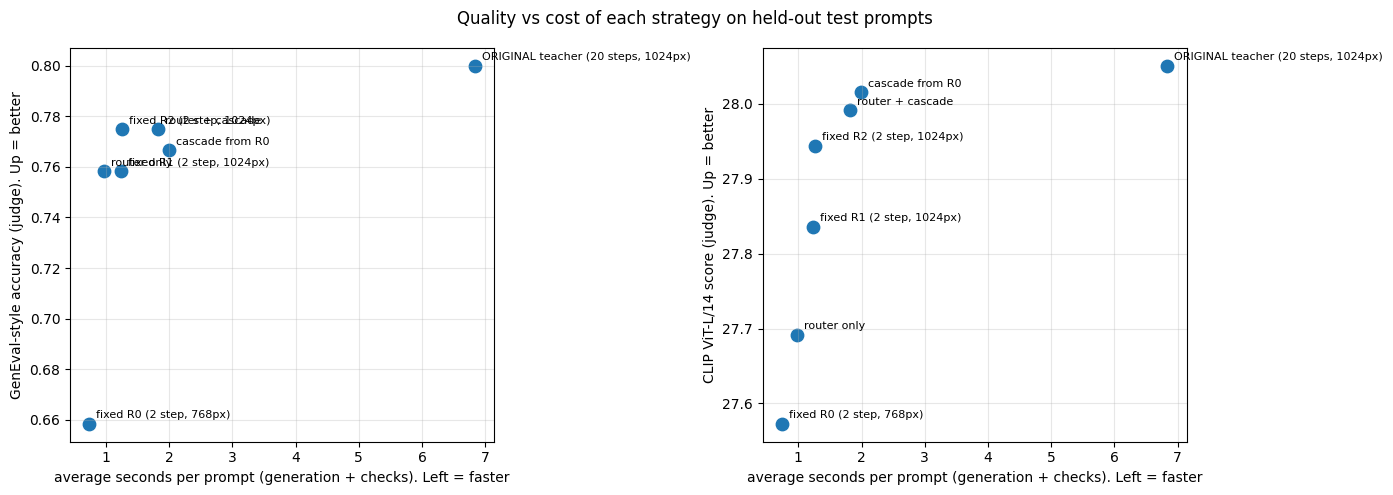

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, col, label in [(axes[0], "geneval_style_acc", "GenEval-style accuracy (judge)"), (axes[1], "clip_L_all", "CLIP ViT-L/14 score (judge)")]:
    ax.scatter(S["avg_latency_s"], S[col], s=80)
    for name, rr in S.iterrows():
        ax.annotate(name, (rr["avg_latency_s"], rr[col]), fontsize=8, xytext=(5, 4), textcoords="offset points")
    ax.set_xlabel("average seconds per prompt (generation + checks). Left = faster")
    ax.set_ylabel(label + ". Up = better")
    ax.grid(alpha=0.3)
plt.suptitle("Quality vs cost of each strategy on held-out test prompts")
plt.tight_layout()
plt.savefig(FIG / "strategies_quality_vs_cost.png", dpi=140)
plt.show()

## 12 · How often does the fast gate agree with the independent judge?
If the gate often says "pass" when the judge says "fail", the cascade stops too early. This table is the honest check.

In [17]:
both = T[T["judge_struct_ok"].notna() & T["gate_struct"].notna()].copy()
both["gate_s"] = as_bool(both["gate_struct"]).astype(bool)
both["judge_s"] = both["judge_struct_ok"].astype(bool)
agreement = pd.crosstab(both["gate_s"].map({True: "gate: pass", False: "gate: fail"}),
                        both["judge_s"].map({True: "judge: pass", False: "judge: fail"}), normalize="all").round(3)
display(agreement)
print(f"Agreement: {(both.gate_s == both.judge_s).mean():.1%} of {len(both)} test pictures; "
      f"gate too lenient (pass but judge fails): {((both.gate_s) & (~both.judge_s)).mean():.1%}")

judge_s,judge: fail,judge: pass
gate_s,,
gate: fail,0.182,0.044
gate: pass,0.065,0.710


Agreement: 89.2% of 573 test pictures; gate too lenient (pass but judge fails): 6.5%


## 13 · Can classical CV replace a more expensive level? (cheapest level + safe polish vs the next level)

In [18]:
coco_pids = sorted({i for i, _ in T.index if T.loc[(i, 0), "source"] == "coco"})
if len(RUNGS) > 1 and coco_pids:
    raw, polished, changed, prompts_ = [], [], 0, []
    for pid in coco_pids:
        im = Image.open(IMG_DIR / f"{pid}_{RUNGS[0]['name']}.jpg").convert("RGB")
        out, inf = pcv.safe_enhance(np.asarray(im), info.loc[pid, "prompt"])
        changed += inf["accepted"]
        raw.append(im)
        polished.append(Image.fromarray(out))
        prompts_.append(info.loc[pid, "prompt"])
    clip_raw = np.mean(judge.clip_scores(raw, prompts_))
    clip_pol = np.mean(judge.clip_scores(polished, prompts_))
    clip_r1 = T.loc[[(i, 1) for i in coco_pids], "judge_clip"].mean()
    print(f"On {len(coco_pids)} COCO test prompts (judge CLIP ViT-L/14):")
    print(f"  {RUNGS[0]['name']} raw              {clip_raw:.2f}   ({LAT[0]:.2f} s)")
    print(f"  {RUNGS[0]['name']} + safe polish    {clip_pol:.2f}   (polish changed {changed} pictures)")
    print(f"  {RUNGS[1]['name']} raw              {clip_r1:.2f}   ({LAT[1]:.2f} s)")

On 80 COCO test prompts (judge CLIP ViT-L/14):
  R0 raw              26.20   (0.74 s)
  R0 + safe polish    26.18   (polish changed 4 pictures)
  R1 raw              26.39   (1.24 s)


## 14 · Examples: when the cascade helped, and when everything failed (for the failure analysis)

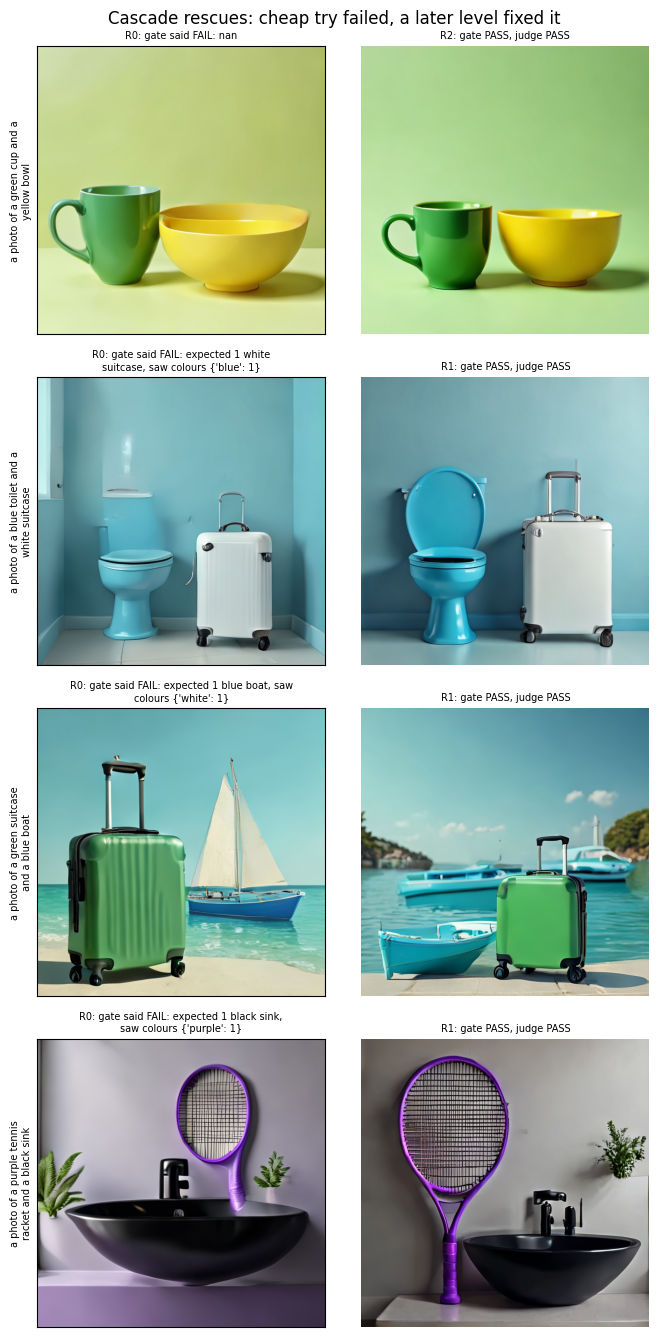

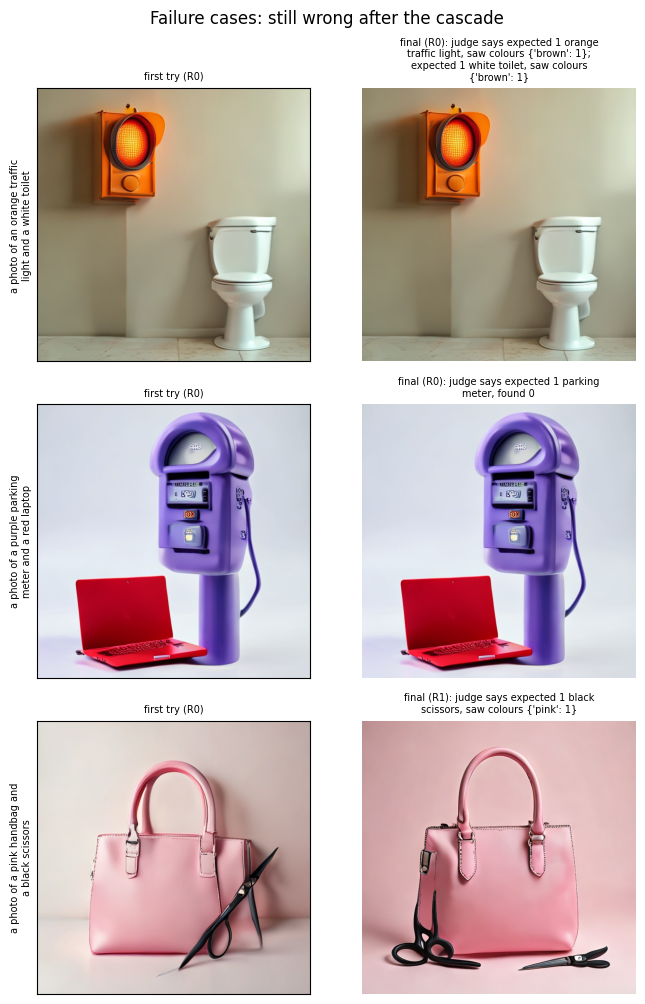

On 120 GenEval test prompts: ours right / original wrong = 9; original right / ours wrong = 12


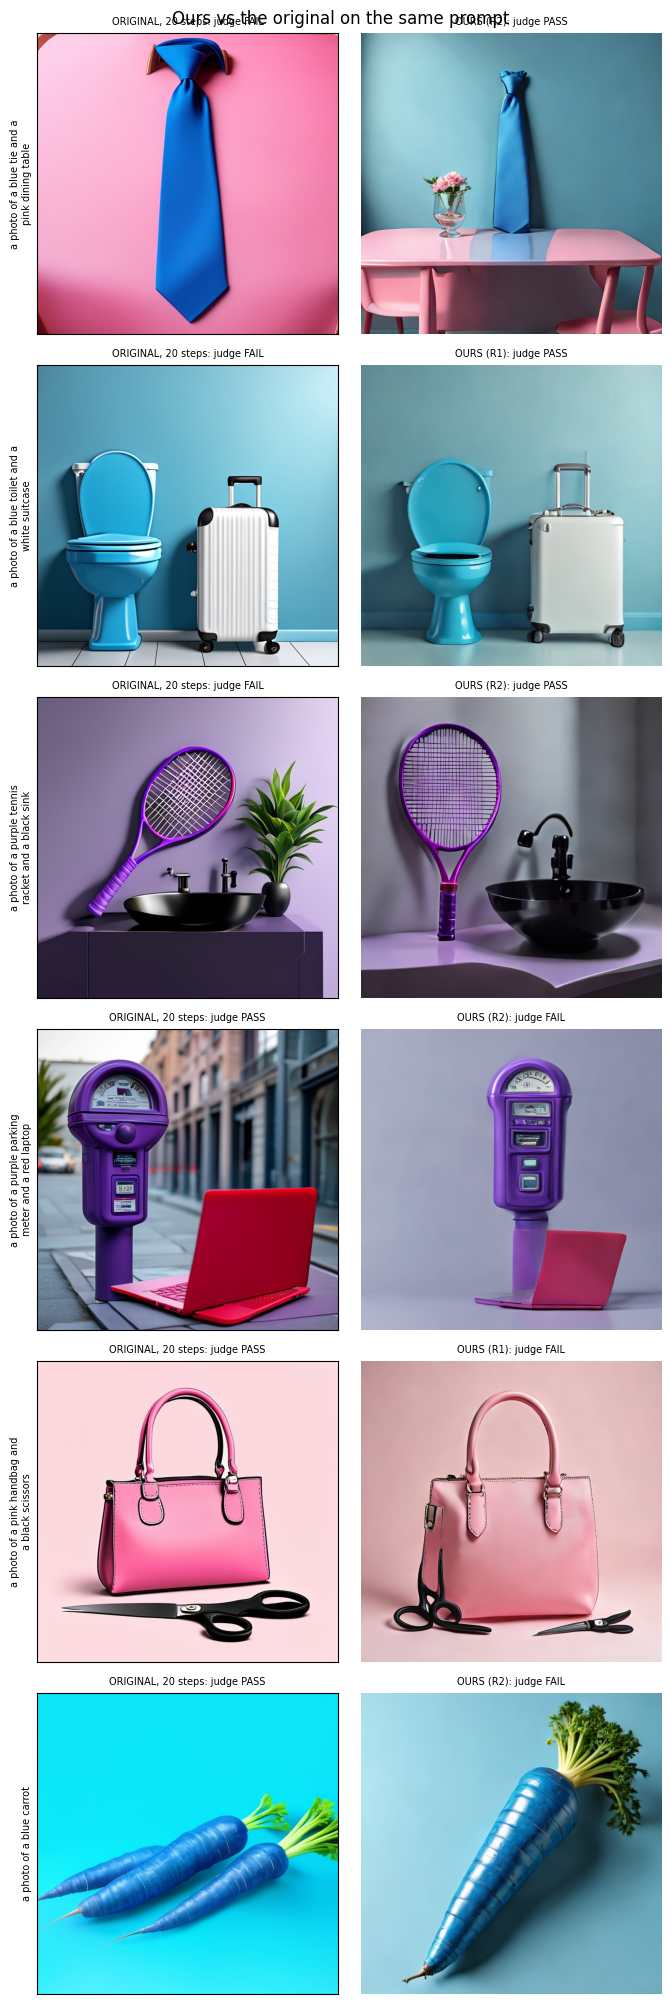

In [19]:
def show(pairs, title, path):
    if not pairs:
        print("No examples for:", title)
        return
    fig, axes = plt.subplots(len(pairs), 2, figsize=(7, 3.4 * len(pairs)))
    axes = np.array(axes).reshape(len(pairs), 2)
    for (a, b, ta, tb, prompt), row in zip(pairs, axes):
        for ax, im, t in zip(row, (a, b), (ta, tb)):
            ax.imshow(im)
            ax.set_title(textwrap.fill(t, 45), fontsize=7)
            ax.axis("off")
        row[0].set_ylabel(textwrap.fill(prompt, 30), fontsize=7)
        row[0].axis("on")
        row[0].set_xticks([])
        row[0].set_yticks([])
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(path, dpi=110)
    plt.show()

casc = results["cascade from R0"]
rescued = casc[(casc.final > 0) & (casc.source == "geneval") & (casc.judge_struct == True)].head(4)
pairs = []
for _, rr in rescued.iterrows():
    first, last = T.loc[(rr.pid, 0)], T.loc[(rr.pid, int(rr.final))]
    pairs.append((Image.open(IMG_DIR / f"{rr.pid}_{RUNGS[0]['name']}.jpg"), Image.open(IMG_DIR / f"{rr.pid}_{RUNGS[int(rr.final)]['name']}.jpg"),
                  f"{RUNGS[0]['name']}: gate said FAIL: {first['gate_reasons'] or 'low match'}",
                  f"{RUNGS[int(rr.final)]['name']}: gate PASS, judge PASS", info.loc[rr.pid, "prompt"]))
show(pairs, "Cascade rescues: cheap try failed, a later level fixed it", FIG / "cascade_rescues.png")

fails = casc[(casc.source == "geneval") & (casc.judge_struct == False)].head(3)
pairs = []
for _, rr in fails.iterrows():
    last = T.loc[(rr.pid, int(rr.final))]
    pairs.append((Image.open(IMG_DIR / f"{rr.pid}_{RUNGS[0]['name']}.jpg"), Image.open(IMG_DIR / f"{rr.pid}_{RUNGS[int(rr.final)]['name']}.jpg"),
                  f"first try ({RUNGS[0]['name']})", f"final ({RUNGS[int(rr.final)]['name']}): judge says {last['judge_reasons']}",
                  info.loc[rr.pid, "prompt"]))
show(pairs, "Failure cases: still wrong after the cascade", FIG / "failure_cases.png")

# Ours vs the original on the same prompt: where each one wins (both directions, for honesty)
if TEACHER_NAME in results:
    ours = results["router + cascade"].set_index("pid")
    orig = results[TEACHER_NAME].set_index("pid")
    common = [pid for pid in ours.index if pid in orig.index and ours.loc[pid, "source"] == "geneval"]
    wins = [pid for pid in common if ours.loc[pid, "judge_struct"] == True and orig.loc[pid, "judge_struct"] == False]
    losses = [pid for pid in common if ours.loc[pid, "judge_struct"] == False and orig.loc[pid, "judge_struct"] == True]
    print(f"On {len(common)} GenEval test prompts: ours right / original wrong = {len(wins)}; "
          f"original right / ours wrong = {len(losses)}")
    pairs = []
    for pid in wins[:3] + losses[:3]:
        fr = int(ours.loc[pid, "final"])
        pairs.append((Image.open(IMG_DIR / f"{pid}_TEACHER.jpg"), Image.open(IMG_DIR / f"{pid}_{RUNGS[fr]['name']}.jpg"),
                      f"ORIGINAL, 20 steps: judge {'PASS' if orig.loc[pid, 'judge_struct'] == True else 'FAIL'}",
                      f"OURS ({RUNGS[fr]['name']}): judge {'PASS' if ours.loc[pid, 'judge_struct'] == True else 'FAIL'}",
                      info.loc[pid, "prompt"]))
    show(pairs, "Ours vs the original on the same prompt", FIG / "ours_vs_original.png")

## 15 · Save everything for the app and the write-up

In [20]:
CASCADE_CONFIG = {
    "model": MODEL_REPO, "te_quant": TE_QUANT, "rungs": RUNGS, "rung_latency_s": RUNG_LAT, "gate_latency_s": GATE_LAT,
    "gate": {"clip_model": GATE_CLIP, "detector": "maskrcnn", "clip_min": CLIP_MIN,
             "visual_unfixable_flags": sorted(pcv.UNFIXABLE), "det_threshold": gate.det_threshold,
             "count_threshold": gate.count_threshold},
    "router": ROUTER_JSON, "mode": MODE_TAG,
}
json.dump(CASCADE_CONFIG, open(SHARED / "cascade_config.json", "w"), indent=1)
shutil.make_archive(str(OUT / f"test_images_{MODE_TAG}"), "zip", IMG_DIR)
lines = ["# Notebook 02b results: router + quality-gated cascade", "",
         f"Mode: {MODE_TAG}. Test prompts: {int(te.sum())} ({len(test_geneval)} official GenEval + {len(coco_test)} COCO val). "
         f"Scores from the independent judge (Mask2Former Swin-S + CLIP ViT-L/14), GenEval-style, not official GenEval.", "",
         "## Checker validation on real COCO photos", "", val_table.to_markdown(), "",
         "## Speed", "", speed.round(3).to_markdown(), "",
         "## Strategies on held-out test prompts", "", S.round(3).to_markdown(), "",
         "## GenEval-style accuracy per task", "", per_task.round(3).to_markdown(), "",
         f"Router: CV accuracy on train {cv.mean():.1%}; test accuracy {np.mean(pred[te] == y[te]):.1%} "
         f"(majority baseline {np.mean(y[te] == majority):.1%}).", "",
         "## Gate vs judge agreement", "", agreement.to_markdown(), ""]
(OUT / f"02b_summary_{MODE_TAG}.md").write_text("\n".join(lines))
print("Saved: cascade_config.json (for the app) to", SHARED, "| summary, CSVs, figures, images zip to", OUT)

Saved: cascade_config.json (for the app) to /content/P3_02b_out/shared | summary, CSVs, figures, images zip to /content/P3_02b_out


## 16 · How to read this, and honest limitations

- **The headline is the strategies table.** It answers "does adaptive generation actually help?". Compare **router + cascade** with the best fixed level: similar judge accuracy at a lower average time is a win. If the router doesn't beat the fixed levels, **say so**: the cascade still adapts to the actual picture.
- **The "vs original" claim comes from the ORIGINAL teacher row:** same prompts, same judge. Only claim "better than the original" if our accuracy is higher there. Otherwise the honest claim is "about as good, N× faster". The "ours vs original" gallery shows wins in **both** directions.
- **Counting is the weakest check.** On cluttered real photos, both checkers confirm only about half of true exact counts (section 6). Read counting scores with care.
- **GenEval-style ≠ official GenEval:** different detector implementation, our own re-implementation of the rules, and QUICK mode uses a subset.
- **Only the 80 COCO object types can be checked structurally.** Other prompts rely on CLIP and the visual check.
- **New seed per level:** a failed composition usually needs a *new* sample, not just more steps on the same one. That's why levels change the seed.
- **Latency is GPU time on a T4.** The live app adds network time, plus packing for the phone (notebook 02a).